# Assignment 5: Representation Learning in PyTorch

**Student ID:** 2025320560____________________  
**Name:**권범준 ____________________

**Grading (100 points)**

| Item | Topic | Points |
|---|---|---:|
| 1.1 | Feature Extraction and kNN Evaluation | 10 |
| 1.2 | Linear Probing | 8 |
| 1.3 | Convolutional Autoencoder | 8 |
| 1.4 | Reconstruction Training with Logging | 10 |
| 1.5 | Reconstruction versus Representation Quality | 8 |
|  | **Part 1 subtotal** | **44** |
| 2.1 | Augmented Views | 8 |
| 2.2 | Contrastive Loss | 12 |
| 2.3 | SimCLR Training with Logging | 10 |
| 2.4 | Reading Contrastive Training Curves | 6 |
| 2.5 | Label Efficiency | 6 |
| 2.6 | Fine-Tuning | 6 |
| 2.7 | Comparing Representations | 8 |
|  | **Part 2 subtotal** | **56** |
|  | **Total** | **100** |


## Assignment Overview

In this assignment, you will learn image representations on CIFAR-10 without
using labels, and evaluate how useful they are for classification. You will
train the same convolutional encoder with two different objectives,
reconstruction and contrastive learning, record what happens during training in
logs, and compare the resulting features with raw pixels, hand-crafted
features, and an untrained encoder. PyTorch autograd computes all backward
passes.

- **Part 1 — Representations and Reconstruction:** Implement feature
  extraction, kNN evaluation, and linear probing, evaluate baseline
  representations, and train an autoencoder and a denoising autoencoder while
  logging both the reconstruction error and the quality of the learned
  features.
- **Part 2 — Contrastive Learning:** Implement augmented views and the InfoNCE
  loss, train a SimCLR model while logging the similarities of positive and
  negative pairs, observe representation collapse and the effect of the
  temperature, fine-tune the learned encoder, and compare all representations,
  including a supervised encoder, under the same evaluation protocol, with
  different amounts of labeled data, and by their invariance and nearest
  neighbors.

### Goals

- Evaluate a representation with kNN classification and linear probing on a
  frozen encoder.
- Implement an autoencoder and train it with a reconstruction loss.
- Construct augmented views and implement the InfoNCE (NT-Xent) loss.
- Log and visualize training dynamics that reveal what a representation
  learns: reconstruction error, kNN accuracy, and positive and negative
  similarities.
- Compare representation learning objectives under consistent evaluation
  conditions and with limited labels, and relate them to supervised learning.
- Distinguish linear probing from fine-tuning.

### References and Conventions

Statements labeled **Lecture Connection** quote the CSAI202 lecture notes
(Lec01–Lec07); each citation names the lecture and the page number of its PDF.
Explanations that go beyond the lecture notes are labeled **Concept
Connection**.

Unless stated otherwise, `N` is batch size, `D` is the feature dimension, `x`
is a batch of CIFAR-10 images of shape `(N, 3, 32, 32)` with values in
`[0, 1]`, `h` is a representation of shape `(N, 256)` produced by the encoder,
and `z` is a projected embedding. Labels are used only to evaluate
representations, never to train an encoder. Every training run writes its log to
`logs/<name>_steps.csv` and `logs/<name>_epochs.csv`.

Run the notebook from top to bottom. Use a GPU runtime
(`Runtime > Change runtime type`); on a Colab T4 GPU the whole notebook takes
about 30 minutes. Do not use `torchvision.transforms`, `F.cosine_similarity`,
`nn.CosineSimilarity`, or `sklearn` in your implementations; they are used only
in the provided reference checks.


## Colab Setup: Download the CIFAR-10 Dataset

CIFAR-10 contains 60,000 color images of size 32x32 in 10 classes (about
170 MB). `torchvision` shows a progress bar while downloading and skips the
download if the files already exist.


In [1]:
from torchvision.datasets import CIFAR10

CIFAR10('datasets', train=True, download=True)
CIFAR10('datasets', train=False, download=True)


100%|██████████| 170M/170M [19:56<00:00, 143kB/s]


Dataset CIFAR10
    Number of datapoints: 10000
    Root location: datasets
    Split: Test

#### Setup


In [2]:
import copy
import csv
import math
import os
import random
from collections import defaultdict

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.datasets import CIFAR10

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0)
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

SEED = 231
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)


def max_relative_error(x, y, eps=1e-8):
    """Return the maximum elementwise relative error between two tensors."""
    x = x.detach().cpu()
    y = y.detach().cpu()
    return ((x - y).abs() / torch.clamp(x.abs() + y.abs(), min=eps)).max().item()


Using device: cuda


#### Provided: CIFAR-10 Data, Mini-Batches, Training Logs, and Plots

The following helpers load CIFAR-10 as tensors with values in `[0, 1]`,
iterate over mini-batches, store training logs as in Assignment 4, plot the
logs of several runs, and show images. You do not need to modify them.


In [3]:
CLASSES = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


def load_cifar10(root='datasets', num_val=5000):
    """
    Load CIFAR-10 as float tensors with values in [0, 1]. The images are not
    normalized here, because the autoencoder reconstructs these values; the
    encoder normalizes its input itself. The last num_val training images form
    the validation set.
    """
    def to_tensors(dataset):
        x = torch.from_numpy(dataset.data).permute(0, 3, 1, 2).float().div(255)
        y = torch.tensor(dataset.targets, dtype=torch.long)
        return x, y

    x_train, y_train = to_tensors(CIFAR10(root, train=True, download=True))
    x_test, y_test = to_tensors(CIFAR10(root, train=False, download=True))
    num_train = len(x_train) - num_val
    return {
        'x_train': x_train[:num_train], 'y_train': y_train[:num_train],
        'x_val': x_train[num_train:], 'y_val': y_train[num_train:],
        'x_test': x_test, 'y_test': y_test,
    }


class TensorLoader:
    """Iterates over (x, y) mini-batches of tensors that already live on the target device."""

    def __init__(self, x, y, batch_size, shuffle=False, seed=SEED):
        self.x, self.y = x, y
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.generator = torch.Generator().manual_seed(seed)

    def __len__(self):
        return math.ceil(len(self.x) / self.batch_size)

    def __iter__(self):
        n = len(self.x)
        order = torch.randperm(n, generator=self.generator) if self.shuffle else torch.arange(n)
        order = order.to(self.x.device)
        for start in range(0, n, self.batch_size):
            index = order[start:start + self.batch_size]
            yield self.x[index], self.y[index]


class TrainingLog:
    """
    Stores the metrics of one training run, as in Assignment 4.

    - log.steps: dict of lists with one entry per iteration
    - log.epochs: dict of lists with one entry per epoch
    - log.save() writes logs/<name>_steps.csv and logs/<name>_epochs.csv
    - TrainingLog.load(name) reads them back
    """

    def __init__(self, name):
        self.name = name
        self.steps = defaultdict(list)
        self.epochs = defaultdict(list)

    def log_step(self, **values):
        for key, value in values.items():
            self.steps[key].append(float(value))

    def log_epoch(self, **values):
        for key, value in values.items():
            self.epochs[key].append(float(value))

    def save(self, log_dir='logs'):
        os.makedirs(log_dir, exist_ok=True)
        for kind, table in [('steps', self.steps), ('epochs', self.epochs)]:
            with open(os.path.join(log_dir, f'{self.name}_{kind}.csv'), 'w', newline='') as f:
                writer = csv.writer(f)
                writer.writerow(table.keys())
                writer.writerows(zip(*table.values()))

    @classmethod
    def load(cls, name, log_dir='logs'):
        log = cls(name)
        for kind, table in [('steps', log.steps), ('epochs', log.epochs)]:
            with open(os.path.join(log_dir, f'{name}_{kind}.csv'), newline='') as f:
                for row in csv.DictReader(f):
                    for key, value in row.items():
                        table[key].append(float(value))
        return log


def moving_average(values, window):
    values = np.asarray(values, dtype=float)
    cumsum = np.concatenate([[0.0], np.cumsum(values)])
    end = np.arange(1, len(values) + 1)
    start = np.maximum(0, end - window)
    return (cumsum[end] - cumsum[start]) / (end - start)


def plot_logs(logs, step_keys=(), epoch_keys=(), smooth=20):
    """
    Plot several runs side by side: one subplot per iteration metric in
    step_keys (moving average over `smooth` iterations) and one per epoch
    metric in epoch_keys. Run i is drawn in color f"C{i}".
    """
    keys = [('steps', k) for k in step_keys] + [('epochs', k) for k in epoch_keys]
    fig, axes = plt.subplots(1, len(keys), figsize=(5 * len(keys), 3.8), squeeze=False)
    for ax, (kind, key) in zip(axes[0], keys):
        for i, log in enumerate(logs):
            table = getattr(log, kind)
            if key not in table:
                continue
            if kind == 'steps':
                ax.plot(table['step'], moving_average(table[key], smooth), color=f'C{i}', label=log.name)
                ax.set_xlabel('iteration')
            else:
                ax.plot(table['epoch'], table[key], 'o-', color=f'C{i}', label=log.name)
                ax.set_xlabel('epoch')
        ax.set_ylabel(key)
        ax.legend(fontsize=8)
    fig.tight_layout()
    return fig


def show_images(rows, row_titles):
    """Show a grid of images: rows is a list of tensors of shape (K, 3, 32, 32)."""
    k = rows[0].shape[0]
    fig, axes = plt.subplots(len(rows), k, figsize=(1.4 * k, 1.5 * len(rows)), squeeze=False)
    for r, (images, title) in enumerate(zip(rows, row_titles)):
        for c in range(k):
            axes[r, c].imshow(images[c].detach().cpu().permute(1, 2, 0).clamp(0, 1).numpy())
            axes[r, c].axis('off')
        axes[r, 0].set_title(title, fontsize=9, loc='left')
    fig.subplots_adjust(left=0.01, right=0.99, bottom=0.01, top=0.95, wspace=0.05, hspace=0.45)
    return fig


In [4]:
# Load CIFAR-10 once and move it to the device. The whole dataset fits in GPU
# memory (about 700 MB), which makes every experiment much faster.
data = {key: value.to(device) for key, value in load_cifar10().items()}
for key, value in data.items():
    print(f'{key}: {tuple(value.shape)}')

# The first 10,000 training images form the bank for kNN evaluation during training.
bank_x, bank_y = data['x_train'][:10000], data['y_train'][:10000]


x_train: (45000, 3, 32, 32)
y_train: (45000,)
x_val: (5000, 3, 32, 32)
y_val: (5000,)
x_test: (10000, 3, 32, 32)
y_test: (10000,)


#### Provided: The Shared Encoder

Every learned representation in this assignment comes from the same
convolutional encoder, so that differences between representations come from
the training objective and not from the architecture. The encoder normalizes
its input with the per-channel mean and standard deviation of the training
images and maps an image to a 256-dimensional representation `h`.

**Lecture Connection**

> An input 𝑥 is transformed into a representation 𝑧  
> Training objectives influence what information the representation preserves  
> *(Lec07 Representation Learning, p. 6)*

> Match encoder capacity and downstream evaluation conditions where feasible  
> *(Lec07 Representation Learning, p. 46)*

| Stage | Shape |
|---|---|
| input `x` | `(N, 3, 32, 32)` |
| after three conv blocks with max pooling | `(N, 256, 4, 4)` |
| after the fourth conv block and global average pooling | `(N, 256)` |


In [5]:
CHANNEL_MEAN = data['x_train'].mean(dim=(0, 2, 3))
CHANNEL_STD = data['x_train'].std(dim=(0, 2, 3))


class Encoder(nn.Module):
    """Provided: maps images (N, 3, 32, 32) in [0, 1] to representations h of shape (N, 256)."""

    def __init__(self, feature_dim=256):
        super().__init__()
        self.register_buffer('mean', CHANNEL_MEAN.view(1, 3, 1, 1).clone())
        self.register_buffer('std', CHANNEL_STD.view(1, 3, 1, 1).clone())

        def block(in_channels, out_channels, pool=True):
            layers = [nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
                      nn.BatchNorm2d(out_channels), nn.ReLU()]
            return layers + ([nn.MaxPool2d(2)] if pool else [])

        self.net = nn.Sequential(
            *block(3, 64), *block(64, 128), *block(128, 256), *block(256, feature_dim, pool=False),
            nn.AdaptiveAvgPool2d(1), nn.Flatten())

    def forward(self, x):
        return self.net((x - self.mean) / self.std)


## Part 1: Representations and Reconstruction (44 points)

A network trained for one task also learns intermediate features, and those
features can be reused for other tasks. In this part you will build the tools
to measure how useful a representation is, apply them to simple baseline
representations, and then learn a representation by reconstructing the input.

**Lecture Connection**

> Neural networks also learn intermediate representations  
> Learned features can support tasks beyond the original training objective  
> Representation learning studies how useful features are acquired  
> *(Lec07 Representation Learning, p. 3)*


### Section 1: Evaluating Representations


#### Question 1.1: Feature Extraction and kNN Evaluation [code] (10 points)

Implement a function that turns images into features, and a k-nearest-neighbor
classifier that measures how well similar features correspond to the same
class.

**Lecture Connection**

> Classification measures the usefulness of features for label prediction  
> Retrieval and clustering provide complementary evaluations  
> *(Lec07 Representation Learning, p. 41)*

> Cosine similarity compares the directions of two vectors  
> L2 normalization makes dot products equivalent to cosine similarity  
> *(Lec07 Representation Learning, p. 30)*

**Concept Connection**

A **kNN evaluation** needs no training: a query is classified by a majority
vote among the `k` bank examples whose features have the highest cosine
similarity with it. If similar images get similar features, the vote is
usually correct, so the kNN accuracy measures how well the geometry of the
feature space reflects the classes.

**Implementation Guide and Point Breakdown**

- **`extract_features` (3 points):** `feature_fn` is either an `nn.Module` (an
  encoder) or a plain function. Modules must be in evaluation mode so that
  batch normalization uses its running statistics. The function is decorated
  with `@torch.no_grad()`.
- **`knn_accuracy` (7 points):** Process the queries in chunks of `batch_size`
  so that the similarity matrix fits in memory. `topk`, `F.one_hot`, and
  `argmax` give a loop-free vote within a chunk.

| Tensor | Shape |
|---|---|
| `x` | `(N, 3, 32, 32)` |
| `features` | `(N, D)` |
| `bank_feats`, `bank_labels` | `(B, D)`, `(B,)` |
| similarities of a chunk of queries | `(batch_size, B)` |
| neighbor labels | `(batch_size, k)` |

**Expected Check:** `extract_features` returns the same features as one direct
call and leaves a module in evaluation mode, and `knn_accuracy` matches a
brute-force loop on a small problem, including ties.


In [6]:
@torch.no_grad()
def extract_features(feature_fn, x, batch_size=1000):
    """
    Inputs:
    - feature_fn: nn.Module or function mapping (B, 3, 32, 32) to (B, D)
    - x: images of shape (N, 3, 32, 32)

    Returns:
    - features: tensor of shape (N, D)
    """
    ############################################################################
    # TODO 1.1 (3/10 points): If feature_fn is an nn.Module, put it in         #
    # evaluation mode. Apply feature_fn to x in chunks of batch_size and       #
    # concatenate the outputs into one (N, D) tensor named `features`.         #
    ############################################################################
    if isinstance(feature_fn, nn.Module):
        feature_fn.eval()
    feature_batches = []
    for start in range(0, x.shape[0], batch_size):
        feature_batches.append(feature_fn(x[start:start + batch_size]))
    features = torch.cat(feature_batches, dim=0)
    ############################################################################
    #                         END OF YOUR CODE                                 #
    ############################################################################
    return features


@torch.no_grad()
def knn_accuracy(bank_feats, bank_labels, query_feats, query_labels, k=20,
                 num_classes=10, batch_size=1000):
    """
    Inputs:
    - bank_feats, bank_labels: labeled reference features (B, D) and labels (B,)
    - query_feats, query_labels: features (Q, D) and labels (Q,) to classify
    - k: number of neighbors

    Returns:
    - accuracy: fraction of queries whose kNN prediction is correct (Python float)
    """
    ############################################################################
    # TODO 1.1 (7/10 points): L2-normalize both feature sets, compute cosine   #
    # similarities between every query and every bank example with one matrix  #
    # multiplication per chunk of queries, take the k most similar bank        #
    # examples, and predict the most frequent label among them (ties go to the #
    # smallest class index). Store the fraction of correct predictions in      #
    # `accuracy`.                                                              #
    ############################################################################
    bank_normalized = F.normalize(bank_feats, p=2, dim=1)
    query_normalized = F.normalize(query_feats, p=2, dim=1)
    correct = 0
    for start in range(0, query_normalized.shape[0], batch_size):
        query_batch = query_normalized[start:start + batch_size]
        similarities = query_batch @ bank_normalized.T
        neighbor_indices = similarities.topk(k=k, dim=1).indices
        neighbor_labels = bank_labels[neighbor_indices]
        votes = F.one_hot(neighbor_labels, num_classes=num_classes).sum(dim=1)
        predictions = votes.argmax(dim=1)
        labels_batch = query_labels[start:start + batch_size]
        correct += (predictions == labels_batch).sum().item()
    accuracy = correct / query_feats.shape[0]
    ############################################################################
    #                         END OF YOUR CODE                                 #
    ############################################################################
    return accuracy


In [7]:
# Provided check: extract_features and knn_accuracy against direct computations.
torch.manual_seed(SEED)
toy_encoder = nn.Sequential(nn.Flatten(), nn.Linear(12, 4), nn.BatchNorm1d(4)).to(device)
toy_x = torch.randn(10, 3, 2, 2, device=device)
toy_encoder.train()
features = extract_features(toy_encoder, toy_x, batch_size=4)
assert not toy_encoder.training, 'extract_features should put a module in evaluation mode'
assert features.shape == (10, 4)
assert max_relative_error(features, toy_encoder(toy_x)) < 1e-6
assert torch.equal(extract_features(lambda x: x.flatten(1), toy_x, batch_size=3), toy_x.flatten(1))


def knn_brute_force(bank_feats, bank_labels, query_feats, query_labels, k, num_classes):
    correct = 0
    for q, label in zip(query_feats, query_labels):
        sims = F.cosine_similarity(bank_feats, q[None], dim=1)
        nearest = sims.argsort(descending=True)[:k]
        counts = torch.bincount(bank_labels[nearest], minlength=num_classes)
        correct += int(counts.argmax().item() == label.item())
    return correct / len(query_feats)


bank = torch.randn(200, 8, dtype=torch.float64)
bank_labels = torch.randint(0, 5, (200,))
queries = torch.randn(50, 8, dtype=torch.float64)
query_labels = torch.randint(0, 5, (50,))
for k in [1, 4, 15]:
    ours = knn_accuracy(bank, bank_labels, queries, query_labels, k=k, num_classes=5, batch_size=16)
    expected = knn_brute_force(bank, bank_labels, queries, query_labels, k, 5)
    print(f'k={k}: accuracy {ours:.3f}, expected {expected:.3f}')
    assert abs(ours - expected) < 1e-12

# A tie between classes 1 and 3 (two votes each) goes to the smaller index, 1.
tie_bank = torch.tensor([[1.0, 0.0], [0.9, 0.1], [0.8, 0.2], [0.7, 0.3], [-1.0, 0.0]])
tie_labels = torch.tensor([3, 1, 3, 1, 0])
assert knn_accuracy(tie_bank, tie_labels, torch.tensor([[1.0, 0.0]]), torch.tensor([1]), k=4, num_classes=4) == 1.0
print('extract_features and knn_accuracy check passed')


k=1: accuracy 0.260, expected 0.260
k=4: accuracy 0.260, expected 0.260
k=15: accuracy 0.280, expected 0.280
extract_features and knn_accuracy check passed


#### Question 1.2: Linear Probing [code] (8 points)

Train a linear classifier on frozen features, log its training curves, and
report its test accuracy at the epoch with the best validation accuracy.

**Lecture Connection**

> Prediction heads map representations to task-specific outputs  
> The quality of intermediate features affects downstream performance  
> *(Lec07 Representation Learning, p. 4)*

> Encoder parameters remain frozen during probing  
> A linear classifier is trained using labeled examples  
> Classification performance measures linear accessibility of task information  
> *(Lec07 Representation Learning, p. 42)*

> Extract encoder features without gradient tracking  
> Evaluate classification accuracy on a held-out test set  
> *(Lec07 Representation Learning, p. 43)*

**Concept Connection**

Because the features are computed once and the encoder is never updated, a
linear probe only measures what the representation already contains. The
features are standardized with the mean and standard deviation of the training
features, so that every representation is probed under the same conditions.
The validation set selects the epoch, and the test set is used only once, at
the selected epoch.

**Implementation Guide and Point Breakdown**

The provided code standardizes the features, creates the classifier, the Adam
optimizer, and the mini-batch loader of features, keeps the classifier from the
epoch with the best validation accuracy, and evaluates it on the test features.

- **One epoch of training (5 points):** Log `step` and `loss` for every
  iteration.
- **Epoch evaluation (3 points):** Log `epoch`, `train_loss`, `train_acc`,
  `val_loss`, and `val_acc`.

| Tensor | Shape |
|---|---|
| `train_feats`, `val_feats`, `test_feats` | `(N_train, D)`, `(N_val, D)`, `(N_test, D)` |
| classifier output | `(N, 10)` |

**Expected Check:** On ten well-separated Gaussian clusters, the probe reaches
a test accuracy of at least `0.95`, and its log contains the keys above with one
row per iteration and one row per epoch.


In [8]:
def linear_probe(train_feats, train_labels, val_feats, val_labels, test_feats, test_labels,
                 name, num_epochs=30, lr=1e-3, batch_size=256, num_classes=10):
    """
    Train a linear classifier on frozen features.

    Returns:
    - log: TrainingLog of the probe (saved to logs/)
    - test_acc: test accuracy of the classifier from the epoch with the best
      validation accuracy (Python float)
    """
    torch.manual_seed(SEED)
    mean, std = train_feats.mean(dim=0), train_feats.std(dim=0) + 1e-6
    train_feats, val_feats, test_feats = [(f - mean) / std for f in (train_feats, val_feats, test_feats)]
    classifier = nn.Linear(train_feats.shape[1], num_classes).to(train_feats.device)
    optimizer = torch.optim.Adam(classifier.parameters(), lr=lr, weight_decay=1e-4)
    train_loader = TensorLoader(train_feats, train_labels, batch_size, shuffle=True)
    log = TrainingLog(name)
    step = 0
    best_val_acc, best_state = -1.0, None

    for epoch in range(1, num_epochs + 1):
        ########################################################################
        # TODO 1.2 (5/8 points): Train the classifier for one epoch on         #
        # train_loader with F.cross_entropy, and log one row per iteration     #
        # with log.log_step using the keys step and loss.                      #
        ########################################################################
        classifier.train()
        for feats_batch, labels_batch in train_loader:
            optimizer.zero_grad()
            logits = classifier(feats_batch)
            loss = F.cross_entropy(logits, labels_batch)
            loss.backward()
            optimizer.step()
            step += 1
            log.log_step(step=step, loss=loss.item())
        ########################################################################
        #                         END OF YOUR CODE                             #
        ########################################################################

        ########################################################################
        # TODO 1.2 (3/8 points): Without gradient tracking, compute the loss   #
        # and accuracy on all training and all validation features, and log    #
        # one row with log.log_epoch using the keys epoch, train_loss,         #
        # train_acc, val_loss, and val_acc.                                    #
        ########################################################################
        classifier.eval()
        with torch.no_grad():
            train_logits = classifier(train_feats)
            train_loss = F.cross_entropy(train_logits, train_labels).item()
            train_acc = (train_logits.argmax(dim=1) == train_labels).float().mean().item()
            val_logits = classifier(val_feats)
            val_loss = F.cross_entropy(val_logits, val_labels).item()
            val_acc = (val_logits.argmax(dim=1) == val_labels).float().mean().item()
            log.log_epoch(epoch=epoch, train_loss=train_loss, train_acc=train_acc,
                          val_loss=val_loss, val_acc=val_acc)
        ########################################################################
        #                         END OF YOUR CODE                             #
        ########################################################################

        if log.epochs['val_acc'][-1] > best_val_acc:
            best_val_acc = log.epochs['val_acc'][-1]
            best_state = {k: v.clone() for k, v in classifier.state_dict().items()}

    classifier.load_state_dict(best_state)
    with torch.no_grad():
        test_acc = (classifier(test_feats).argmax(dim=1) == test_labels).float().mean().item()
    log.save()
    return log, test_acc


In [9]:
# Provided check: a linear probe on ten well-separated Gaussian clusters.
torch.manual_seed(SEED)
centers = 4 * torch.randn(10, 16, device=device)


def gaussian_clusters(n):
    labels = torch.arange(n, device=device) % 10
    return centers[labels] + torch.randn(n, 16, device=device), labels


(tr_f, tr_y), (va_f, va_y), (te_f, te_y) = gaussian_clusters(500), gaussian_clusters(200), gaussian_clusters(200)
toy_log, toy_test_acc = linear_probe(tr_f, tr_y, va_f, va_y, te_f, te_y, name='check_probe',
                                     num_epochs=30, lr=1e-2)
print('test accuracy:', toy_test_acc)
assert toy_test_acc >= 0.95
reloaded = TrainingLog.load('check_probe')
assert set(reloaded.steps) == {'step', 'loss'}, set(reloaded.steps)
assert set(reloaded.epochs) == {'epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc'}, set(reloaded.epochs)
assert len(reloaded.steps['loss']) == 30 * math.ceil(500 / 256)
assert reloaded.epochs['epoch'] == [float(e) for e in range(1, 31)]
print('linear_probe check passed')


test accuracy: 1.0
linear_probe check passed


#### Provided: Baseline Representations

Before learning any representation, we evaluate three baselines with your kNN
evaluation and linear probe:

- **Raw pixels:** the 3,072 pixel values of each image.
- **Hand-crafted features:** a histogram of gradient orientations over 4 x 4
  cells (similar to HOG) and a joint color histogram, as in the "Image
  Features" exercise of CS231n Assignment 1 (208 values per image).
- **Random encoder:** the shared encoder with its random initialization,
  never trained.

The kNN evaluation uses the 45,000 training images as the bank and the test
images as queries. The results are stored in `results` and compared again at
the end of the assignment.

**Lecture Connection**

> Raw images are represented by numerical pixel values  
> Small visual transformations can cause substantial changes in pixel values  
> Semantically similar images may look different at the pixel level  
> *(Lec07 Representation Learning, p. 5)*


raw_pixels       dim  3072: kNN 0.350, linear probe 0.383
hand_crafted     dim   208: kNN 0.472, linear probe 0.547
random_encoder   dim   256: kNN 0.432, linear probe 0.507


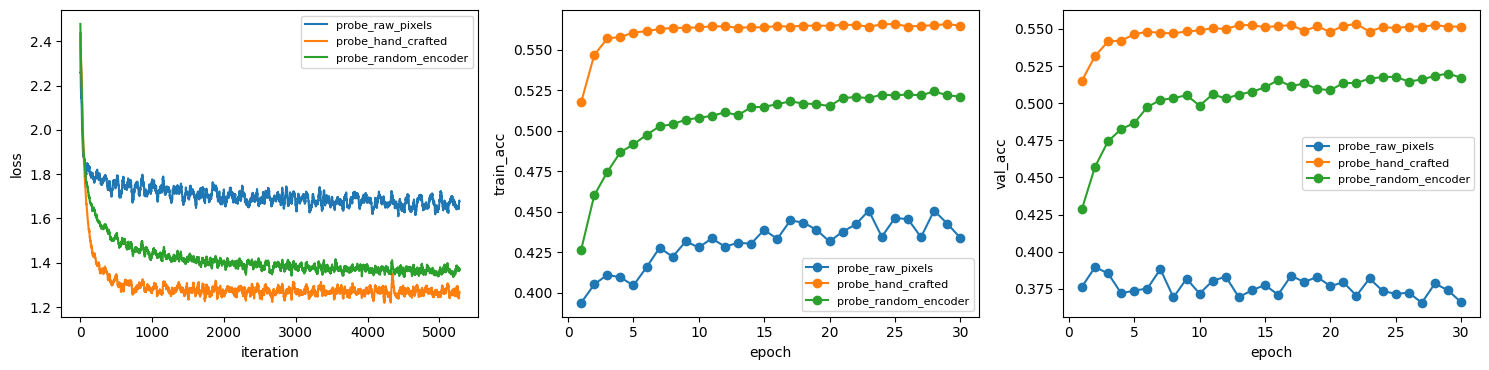

In [10]:
# Provided: hand-crafted features and the evaluation of the three baseline representations.
@torch.no_grad()
def handcrafted_features(x, cell=8, bins=9, color_bins=4):
    """Provided: gradient-orientation histograms over 8x8 cells and a joint RGB color histogram."""
    gray = 0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3]
    gx = F.conv2d(gray, torch.tensor([[[[-1.0, 0.0, 1.0]]]], device=x.device), padding=(0, 1))
    gy = F.conv2d(gray, torch.tensor([[[[-1.0], [0.0], [1.0]]]], device=x.device), padding=(1, 0))
    magnitude = torch.sqrt(gx ** 2 + gy ** 2)
    orientation = torch.atan2(gy, gx) % math.pi
    bin_index = (orientation / math.pi * bins).long().clamp(max=bins - 1)
    histogram = torch.zeros(x.shape[0], bins, *x.shape[2:], device=x.device)
    histogram.scatter_(1, bin_index, magnitude)
    hog = F.avg_pool2d(histogram, cell).flatten(1)
    quantized = (x * color_bins).long().clamp(max=color_bins - 1)
    code = (quantized[:, 0] * color_bins + quantized[:, 1]) * color_bins + quantized[:, 2]
    color = F.one_hot(code.flatten(1), color_bins ** 3).float().mean(dim=1)
    return torch.cat([hog, color], dim=1)


def evaluate_features(name, feature_fn):
    """Provided: kNN and linear-probe test accuracy of one representation."""
    feats = {split: extract_features(feature_fn, data[f'x_{split}']) for split in ['train', 'val', 'test']}
    knn = knn_accuracy(feats['train'], data['y_train'], feats['test'], data['y_test'])
    log, linear = linear_probe(feats['train'], data['y_train'], feats['val'], data['y_val'],
                               feats['test'], data['y_test'], name=f'probe_{name}')
    print(f"{name:16s} dim {feats['train'].shape[1]:5d}: kNN {knn:.3f}, linear probe {linear:.3f}")
    return {'feats': feats, 'knn': knn, 'linear': linear, 'probe_log': log}


torch.manual_seed(SEED)
random_encoder = Encoder().to(device)
results = {
    'raw_pixels': evaluate_features('raw_pixels', lambda x: x.flatten(1)),
    'hand_crafted': evaluate_features('hand_crafted', handcrafted_features),
    'random_encoder': evaluate_features('random_encoder', random_encoder),
}
plot_logs([results[name]['probe_log'] for name in results], step_keys=['loss'],
          epoch_keys=['train_acc', 'val_acc'])
plt.show()


### Section 2: Autoencoders


#### Question 1.3: Convolutional Autoencoder [code] (8 points)

Build a decoder that maps the 256-dimensional representation of the shared
encoder back to an image, and combine both into an autoencoder.

**Lecture Connection**

> An encoder converts the input into a latent representation  
> A decoder reconstructs the input from the latent representation  
> Manual class labels are not required  
> *(Lec07 Representation Learning, p. 12)*

> A bottleneck limits the capacity of the intermediate representation  
> The encoder must preserve information useful for reconstruction  
> *(Lec07 Representation Learning, p. 13)*

> A sigmoid output matches inputs scaled to the range zero to one  
> *(Lec07 Representation Learning, p. 15)*

**Concept Connection**

A transposed convolution with kernel size 4, stride 2, and padding 1 doubles the
height and width of its input, so three of them turn a `4 x 4` map into a
`32 x 32` image. The representation `h` has 256 values while an image has
3,072, so the autoencoder must compress every image by a factor of 12.

**Implementation Guide and Point Breakdown**

- **`Decoder.__init__` (4 points):** Define the layers in the table below.
- **`Decoder.forward` (2 points):** Apply `self.fc`, reshape, and apply
  `self.net`.
- **`Autoencoder.forward` (2 points):** Return both `h` and `x_hat`.

| Layer | Output shape |
|---|---|
| `self.fc`: `nn.Linear(256, 256 * 4 * 4)`, then reshape | `(N, 256, 4, 4)` |
| `nn.ConvTranspose2d(256, 128, 4, stride=2, padding=1)`, `nn.BatchNorm2d(128)`, `nn.ReLU()` | `(N, 128, 8, 8)` |
| `nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1)`, `nn.BatchNorm2d(64)`, `nn.ReLU()` | `(N, 64, 16, 16)` |
| `nn.ConvTranspose2d(64, 3, 4, stride=2, padding=1)`, `nn.Sigmoid()` | `(N, 3, 32, 32)` |

`self.net` is an `nn.Sequential` of the last three rows.

**Expected Check:** The layer types, the number of parameters (1,711,683 in
the decoder), and the output shapes match the table, and every reconstructed
value lies in `[0, 1]`.


In [11]:
class Decoder(nn.Module):
    """Maps representations h of shape (N, 256) back to images of shape (N, 3, 32, 32)."""

    def __init__(self, feature_dim=256):
        super().__init__()
        ########################################################################
        # TODO 1.3 (4/8 points): Define self.fc and self.net as described in   #
        # the table above.                                                     #
        ########################################################################
        self.fc = nn.Linear(feature_dim, 256 * 4 * 4)
        self.net = nn.Sequential(
            nn.ConvTranspose2d(256, 128, 4, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.ConvTranspose2d(64, 3, 4, stride=2, padding=1),
            nn.Sigmoid()
        )
        ########################################################################
        #                         END OF YOUR CODE                             #
        ########################################################################

    def forward(self, h):
        ########################################################################
        # TODO 1.3 (2/8 points): Map h with self.fc, reshape the result to (N, #
        # 256, 4, 4), and apply self.net.                                      #
        ########################################################################
        x_hat = self.fc(h)
        x_hat = x_hat.reshape(h.shape[0], 256, 4, 4)
        x_hat = self.net(x_hat)
        ########################################################################
        #                         END OF YOUR CODE                             #
        ########################################################################
        return x_hat


class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = Encoder()
        self.decoder = Decoder()

    def forward(self, x):
        """
        Returns:
        - h: representation of shape (N, 256)
        - x_hat: reconstruction of shape (N, 3, 32, 32)
        """
        ########################################################################
        # TODO 1.3 (2/8 points): Encode x into h and decode h into x_hat.      #
        ########################################################################
        h = self.encoder(x)
        x_hat = self.decoder(h)
        ########################################################################
        #                         END OF YOUR CODE                             #
        ########################################################################
        return h, x_hat


In [12]:
# Provided check: architecture, parameter count, and output shapes of the autoencoder.
torch.manual_seed(SEED)
toy_ae = Autoencoder().to(device)
assert [type(layer).__name__ for layer in toy_ae.decoder.net] == [
    'ConvTranspose2d', 'BatchNorm2d', 'ReLU', 'ConvTranspose2d', 'BatchNorm2d', 'ReLU',
    'ConvTranspose2d', 'Sigmoid']
num_params = sum(p.numel() for p in toy_ae.decoder.parameters())
print('decoder parameters:', num_params)
assert num_params == 1711683
h, x_hat = toy_ae(data['x_val'][:5])
assert h.shape == (5, 256) and x_hat.shape == (5, 3, 32, 32)
assert x_hat.min() >= 0 and x_hat.max() <= 1
print('Autoencoder check passed')


decoder parameters: 1711683
Autoencoder check passed


#### Question 1.4: Reconstruction Training with Logging [code] (10 points)

Train an autoencoder with a reconstruction loss, optionally on corrupted
inputs, and log both how well it reconstructs and how useful its encoder
features are.

**Lecture Connection**

> Mean squared error measures average squared reconstruction differences  
> Gradients update both encoder and decoder parameters  
> *(Lec07 Representation Learning, p. 14)*

> Reconstruction loss replaces classification loss  
> *(Lec07 Representation Learning, p. 16)*

> The encoder receives a corrupted input  
> The decoder attempts to recover the clean input  
> Denoising does not require additional manual labels  
> *(Lec07 Representation Learning, p. 17)*

**Concept Connection**

A **denoising autoencoder** receives $\tilde x = \mathrm{clip}(x + \epsilon)$ with
Gaussian noise $\epsilon \sim \mathcal{N}(0, \sigma^2)$ but must reconstruct the
clean $x$, so it cannot simply copy its input. The reconstruction error alone
does not tell us whether the features are useful, so the log also records the
kNN accuracy of the encoder features after every epoch. Labels are used only
for this evaluation, never for training.

**Implementation Guide and Point Breakdown**

- **`corrupt` (2 points):** Add noise and clamp.
- **Training iteration (5 points):** The reconstruction target is always the
  clean `x`. Log `step` and `loss`.
- **Epoch evaluation (3 points):** `val_mse` is the mean squared error over all
  values of all validation images, computed in chunks with `val_loader`. Use
  your `extract_features` and `knn_accuracy` for `knn_acc`. Log `epoch`,
  `val_mse`, and `knn_acc`.

| Logged per | Keys |
|---|---|
| iteration | `step`, `loss` |
| epoch | `epoch`, `val_mse`, `knn_acc` |

**Expected Check:** `corrupt` adds noise of the requested scale and stays in
`[0, 1]`, and training on 1,024 images for three epochs lowers the training
reconstruction loss and writes the log keys above.


In [13]:
def corrupt(x, noise_std):
    """Return a corrupted copy of x for denoising (x itself if noise_std is 0)."""
    ############################################################################
    # TODO 1.4 (2/10 points): Return x plus Gaussian noise with standard       #
    # deviation noise_std, clamped to [0, 1]. If noise_std is 0, return x      #
    # unchanged.                                                               #
    ############################################################################
    if noise_std == 0:
        x_noisy = x
    else:
        x_noisy = (x + torch.randn_like(x) * noise_std).clamp(0, 1)
    ############################################################################
    #                         END OF YOUR CODE                                 #
    ############################################################################
    return x_noisy


def train_autoencoder(model, name, num_epochs=10, noise_std=0.0, lr=1e-3, batch_size=256,
                      train_x=None):
    """
    Train model (an Autoencoder) to reconstruct clean images from inputs
    corrupted with Gaussian noise of standard deviation noise_std.

    Returns:
    - log: TrainingLog of the run (saved to logs/)
    """
    torch.manual_seed(SEED)
    train_x = data['x_train'] if train_x is None else train_x
    loader = TensorLoader(train_x, torch.zeros(len(train_x), device=train_x.device),
                          batch_size, shuffle=True)
    val_loader = TensorLoader(data['x_val'], data['y_val'], batch_size=1000)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    log = TrainingLog(name)
    step = 0

    for epoch in range(1, num_epochs + 1):
        model.train()
        for x, _ in loader:
            ####################################################################
            # TODO 1.4 (5/10 points): Corrupt the input with noise_std,        #
            # reconstruct it, compute the mean squared error against the clean #
            # x, update the model, and log one row with log.log_step using the #
            # keys step and loss.                                              #
            ####################################################################
            x_noisy = corrupt(x, noise_std)
            optimizer.zero_grad()
            _, x_hat = model(x_noisy)
            loss = F.mse_loss(x_hat, x)
            loss.backward()
            optimizer.step()
            log.log_step(step=step, loss=loss.item())
            ####################################################################
            #                         END OF YOUR CODE                         #
            ####################################################################
            step += 1

        ########################################################################
        # TODO 1.4 (3/10 points): In evaluation mode and without gradient      #
        # tracking, compute the mean squared reconstruction error on the clean #
        # validation images (val_mse). Then measure the kNN accuracy of the    #
        # encoder features with bank_x/bank_y as the bank and the validation   #
        # set as the queries (knn_acc). Log both with log.log_epoch together   #
        # with the epoch number.                                               #
        ########################################################################
        model.eval()
        with torch.no_grad():
            total_squared_error = 0.0
            total_elements = 0
            for x_val, _ in val_loader:
                _, x_hat = model(x_val)
                total_squared_error += F.mse_loss(x_hat, x_val, reduction='sum').item()
                total_elements += x_val.numel()
            val_mse = total_squared_error / total_elements
            bank_feats = extract_features(model.encoder, bank_x)
            val_feats = extract_features(model.encoder, data['x_val'])
            knn_acc = knn_accuracy(bank_feats, bank_y, val_feats, data['y_val'])
            log.log_epoch(epoch=epoch, val_mse=val_mse, knn_acc=knn_acc)
        ########################################################################
        #                         END OF YOUR CODE                             #
        ########################################################################
        print(f"[{name}] epoch {epoch:2d}/{num_epochs}: train loss {log.steps['loss'][-1]:.4f}, "
              f"val mse {log.epochs['val_mse'][-1]:.4f}, kNN acc {log.epochs['knn_acc'][-1]:.3f}")

    log.save()
    return log


In [14]:
# Provided check: corrupt and a short training run.
torch.manual_seed(SEED)
x = data['x_val'][:200]
assert corrupt(x, 0.0) is x or torch.equal(corrupt(x, 0.0), x)
noisy = corrupt(x, 0.2)
assert noisy.shape == x.shape and noisy.min() >= 0 and noisy.max() <= 1
inside = (x > 0.3) & (x < 0.7)   # far from the clamp, the noise is unchanged
print('noise std inside (0.3, 0.7):', (noisy - x)[inside].std().item())
assert abs((noisy - x)[inside].std().item() - 0.2) < 0.01

torch.manual_seed(SEED)
check_log = train_autoencoder(Autoencoder().to(device), 'check_autoencoder', num_epochs=3,
                              train_x=data['x_train'][:1024])
reloaded = TrainingLog.load('check_autoencoder')
assert set(reloaded.steps) == {'step', 'loss'}
assert set(reloaded.epochs) == {'epoch', 'val_mse', 'knn_acc'}
assert len(reloaded.steps['loss']) == 3 * 4
assert np.mean(reloaded.steps['loss'][-4:]) < np.mean(reloaded.steps['loss'][:4])
print('train_autoencoder check passed')


noise std inside (0.3, 0.7): 0.19465819001197815
[check_autoencoder] epoch  1/3: train loss 0.0623, val mse 0.0608, kNN acc 0.292
[check_autoencoder] epoch  2/3: train loss 0.0512, val mse 0.0617, kNN acc 0.280
[check_autoencoder] epoch  3/3: train loss 0.0475, val mse 0.0717, kNN acc 0.264
train_autoencoder check passed


#### Provided: Autoencoder and Denoising Autoencoder

The cell below trains two autoencoders on the 45,000 training images for 10
epochs each: one on clean inputs and one on inputs corrupted with noise of
standard deviation `0.2`. The plots compare their logs, and the image grid
shows validation images, their corrupted versions, and both reconstructions.
You will interpret these results in Question 1.5.

**Lecture Connection**

> Pixel reconstruction emphasizes information required to reproduce the input  
> Downstream evaluation is needed to assess representation usefulness  
> *(Lec07 Representation Learning, p. 18)*

**Expected Check:** The validation reconstruction error of both runs decreases
by at least 20% from the first to the last epoch.


[autoencoder] epoch  1/10: train loss 0.0210, val mse 0.0213, kNN acc 0.389
[autoencoder] epoch  2/10: train loss 0.0145, val mse 0.0161, kNN acc 0.423
[autoencoder] epoch  3/10: train loss 0.0122, val mse 0.0128, kNN acc 0.426
[autoencoder] epoch  4/10: train loss 0.0111, val mse 0.0115, kNN acc 0.424
[autoencoder] epoch  5/10: train loss 0.0094, val mse 0.0105, kNN acc 0.423
[autoencoder] epoch  6/10: train loss 0.0091, val mse 0.0096, kNN acc 0.423
[autoencoder] epoch  7/10: train loss 0.0083, val mse 0.0088, kNN acc 0.421
[autoencoder] epoch  8/10: train loss 0.0078, val mse 0.0087, kNN acc 0.422
[autoencoder] epoch  9/10: train loss 0.0076, val mse 0.0080, kNN acc 0.415
[autoencoder] epoch 10/10: train loss 0.0069, val mse 0.0075, kNN acc 0.418
[denoising_autoencoder] epoch  1/10: train loss 0.0203, val mse 0.0346, kNN acc 0.384
[denoising_autoencoder] epoch  2/10: train loss 0.0141, val mse 0.0280, kNN acc 0.408
[denoising_autoencoder] epoch  3/10: train loss 0.0122, val mse 0.03

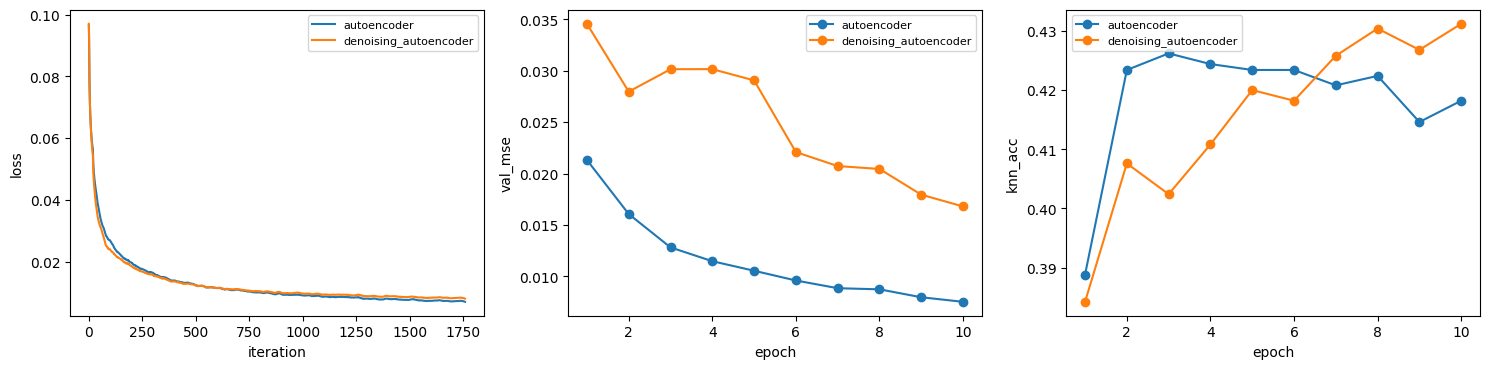

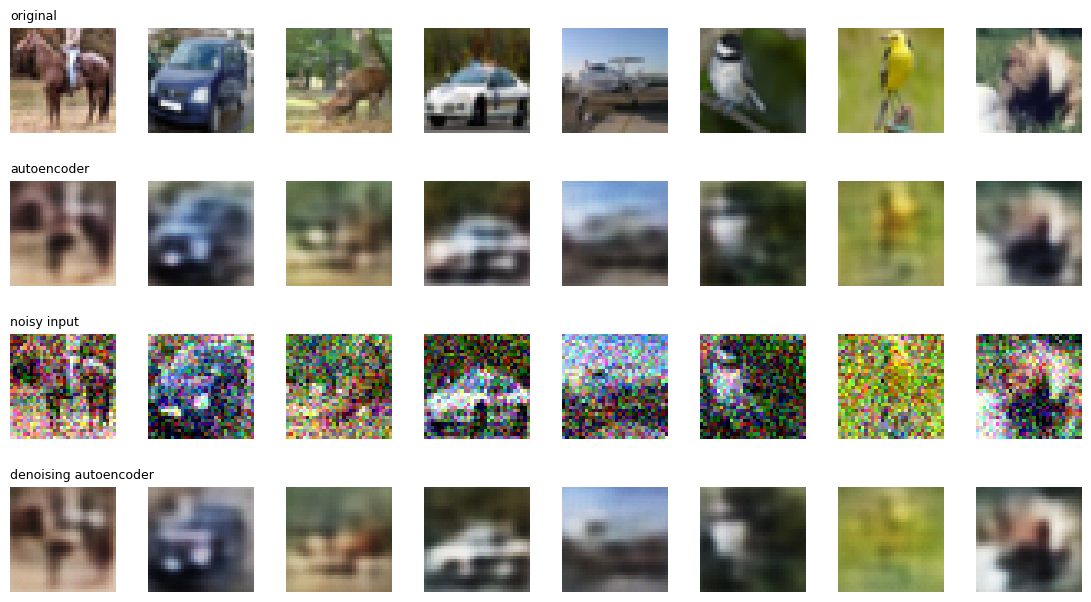

In [15]:
# Provided: train an autoencoder and a denoising autoencoder.
torch.manual_seed(SEED)
autoencoder = Autoencoder().to(device)
ae_log = train_autoencoder(autoencoder, 'autoencoder', noise_std=0.0)

torch.manual_seed(SEED)
denoising_autoencoder = Autoencoder().to(device)
dae_log = train_autoencoder(denoising_autoencoder, 'denoising_autoencoder', noise_std=0.2)

plot_logs([ae_log, dae_log], step_keys=['loss'], epoch_keys=['val_mse', 'knn_acc'])
plt.show()

torch.manual_seed(SEED)
originals = data['x_val'][:8]
noisy = corrupt(originals, 0.2)
autoencoder.eval()
denoising_autoencoder.eval()
with torch.no_grad():
    rows = [originals, autoencoder(originals)[1], noisy, denoising_autoencoder(noisy)[1]]
show_images(rows, ['original', 'autoencoder', 'noisy input', 'denoising autoencoder'])
plt.show()


In [16]:
# Provided check: both autoencoders learned to reconstruct.
for log in [ae_log, dae_log]:
    first, last = log.epochs['val_mse'][0], log.epochs['val_mse'][-1]
    print(f'{log.name}: val mse {first:.4f} -> {last:.4f}, kNN acc {log.epochs["knn_acc"][0]:.3f} -> {log.epochs["knn_acc"][-1]:.3f}')
    assert last <= 0.8 * first
print('Autoencoder training check passed')


autoencoder: val mse 0.0213 -> 0.0075, kNN acc 0.389 -> 0.418
denoising_autoencoder: val mse 0.0346 -> 0.0168, kNN acc 0.384 -> 0.431
Autoencoder training check passed


#### Question 1.5: Reconstruction versus Representation Quality [written] (8 points)

---

Answer using the logs, plots, and reconstructions of the two autoencoders:

1. Compare how `val_mse` and `knn_acc` change during training. What does this
   tell you about the relationship between reconstruction error and the
   usefulness of a representation? Explain why. (3 points)
2. Compare the autoencoder and the denoising autoencoder: their
   reconstructions, their final `val_mse`, and their `knn_acc`. What does the
   denoising objective change in what the encoder must learn? (3 points)
3. The representation has 256 values for an image of 3,072 values. What could
   go wrong if the representation were as large as the input or larger, and
   what could go wrong if it were very small? (2 points)

$\color{blue}{\textit Your Answer:}$

<!-- ANSWER_START: 1.5 -->

*Fill this in*

1. 일반 오토인코더의 검증 MSE는 첫 epoch의 0.0213에서 마지막 epoch의 0.0075로 감소했지만, kNN 정확도는 0.389에서 0.418로 비교적 작게 증가했다. 특히 3번째 epoch 이후에는 MSE가 0.0128에서 0.0075로 계속 감소하는 동안, kNN 정확도는 0.426에서 0.418로 오히려 낮아졌다. 디노이징 오토인코더도 validation MSE가 0.0346에서 0.0168로 감소하고 kNN 정확도가 0.384에서 0.431로 증가했지만, 두 지표가 매 epoch마다 일관되게 함께 개선된 것은 아니었다. 이 결과는 재구성 오차가 작다고 반드시 분류에 더 유용한 표현을 학습한 것은 아니라는 점을 보여준다. 재구성 MSE는 픽셀 값을 얼마나 정확히 복원하는지를 평가하지만, kNN 정확도는 같은 클래스의 이미지들이 표현 공간에서 얼마나 가까이 모이는지를 평가한다. 색상, 배경, 질감 등은 이미지 복원에는 유용해도 클래스 구분에 반드시 중요한 정보는 아니다. 따라서 표현의 유용성은 재구성 오차만으로 판단할 수 없으며, kNN과 같은 다운스트림 평가를 함께 확인해야 한다.

2.재구성 이미지를 보면 일반 오토인코더는 원본의 대략적인 색상과 물체 형태를 복원하지만, 세부 질감과 경계가 흐릿해졌다. 디노이징 오토인코더는 입력에 추가된 강한 노이즈를 상당 부분 제거하고 물체의 대략적인 형태와 색상을 복원했지만, 이 역시 세부 정보는 흐릿하게 나타났다. 일반 오토인코더의 최종 검증 MSE는 0.0075로, 디노이징 오토인코더의 0.0168보다 낮았다. 반면 최종 kNN 정확도는 디노이징 오토인코더가 0.431로, 일반 오토인코더의 0.418보다 높았다. 즉, 이번 실험에서는 깨끗한 입력의 재구성 성능이 더 좋은 모델과 분류에 더 유용한 표현을 가진 모델이 일치하지 않았다. 일반 오토인코더는 깨끗한 입력 자체를 복원하지만, 디노이징 오토인코더는 노이즈가 추가된 입력에서 깨끗한 원본을 복원한다. 따라서 디노이징 인코더는 관측된 픽셀을 그대로 보존하기보다 무작위 노이즈와 원본의 구조를 구분하고, 복원에 유용한 안정적인 정보를 추출해야 한다. 이러한 학습 목적은 노이즈에 강한 표현을 유도할 수 있으며, 이번 실험의 더 높은 최종 kNN 정확도는 이러한 해석과 부합한다. 다만 이 결과만으로 디노이징이 항상 더 높은 분류 성능을 보장한다고 일반화할 수는 없다.

3. 현재 모델은 3,072개 값으로 이루어진 입력을 256개 값으로 압축한다. 표현 크기가 입력과 같거나 더 크면, 모델이 중요한 구조를 추출하기보다 입력을 그대로 전달하는 방식으로 학습할 수 있다. 이 경우 재구성 오차는 낮아도 불필요한 세부 정보나 노이즈까지 보존하여, 클래스 구분에 유용한 표현을 학습하지 못할 수 있다. 반대로 표현이 너무 작으면 압축 과정에서 원본 복원과 클래스 구분에 필요한 정보까지 손실될 수 있다. 그 결과 물체의 형태나 세부 특징을 충분히 보존하지 못해 재구성 품질과 분류 성능이 모두 낮아질 수 있다. 따라서 중요한 구조는 보존하면서 불필요한 정보는 줄일 수 있는 적절한 표현 크기가 필요하다.

<!-- ANSWER_END: 1.5 -->

---


## Part 2: Contrastive Learning (56 points)

Instead of reconstructing pixels, contrastive learning trains the encoder to
recognize two augmented views of the same image among views of other images.
In this part you will implement the views and the loss, train a SimCLR model,
watch what its logs reveal, and finally compare every representation of this
assignment under the same evaluation protocol.

**Lecture Connection**

> Related examples are encouraged to have similar representations  
> Competing examples are encouraged to be distinguishable  
> Automatically constructed relationships can replace manual class labels  
> *(Lec07 Representation Learning, p. 28)*


### Section 3: Views and the Contrastive Loss


#### Question 2.1: Augmented Views [code] (8 points)

Implement color jitter and random grayscale for a whole batch of images on the
GPU. Together with the provided random crop and flip, they create the two
views of every image.

**Lecture Connection**

> Random cropping changes visible image regions  
> Horizontal flipping changes image orientation  
> Color jitter changes appearance without necessarily changing object identity  
> The same augmentation policy is applied independently to each view  
> *(Lec07 Representation Learning, p. 23)*

> The transformations influence which information becomes invariant  
> *(Lec07 Representation Learning, p. 22)*

**Concept Connection**

With $g(x)$ the grayscale image $0.299R + 0.587G + 0.114B$ (`rgb_to_gray`) and
factors $b, c, s \sim U[1-\text{strength}, 1+\text{strength}]$ sampled for every
image, the three color changes are

$$
x \leftarrow b\,x,\qquad
x \leftarrow c\,(x - \bar g) + \bar g,\qquad
x \leftarrow s\,(x - g(x)) + g(x),
$$

where $\bar g$ is the mean of $g(x)$ over the image. A factor of 1 leaves the
image unchanged; contrast and saturation move pixels away from or toward the
gray reference.

**Implementation Guide and Point Breakdown**

- **`color_jitter` (5 points):** Use `torch.empty(N, 1, 1, 1).uniform_(...)`
  for the factors and `torch.rand(N, 1, 1, 1) < p` with `torch.where` to apply
  the jitter only to some images.
- **`random_grayscale` (3 points):** Same pattern with `rgb_to_gray`.

| Tensor | Shape |
|---|---|
| `x`, output | `(N, 3, 32, 32)` |
| `rgb_to_gray(x)` | `(N, 1, 32, 32)` |
| per-image factors and masks | `(N, 1, 1, 1)` |

**Expected Check:** Outputs keep their shape and stay in `[0, 1]`; `p = 0` and
`strength = 0` leave images unchanged; about a fraction `p` of the images is
changed; gray images stay gray; a constant image is scaled by a brightness
factor in `[0.6, 1.4]`; and grayscale images have three equal channels.


In [17]:
def rgb_to_gray(x):
    """Provided: luminance of (N, 3, H, W) images as (N, 1, H, W)."""
    return 0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3]


def random_resized_crop_flip(x, scale=(0.2, 1.0), ratio=(3 / 4, 4 / 3)):
    """
    Provided: for every image, crop a random region covering a fraction `scale`
    of the image with aspect ratio in `ratio`, resize it back to 32x32, and flip
    it horizontally with probability 0.5 (one affine warp per image).
    """
    N = x.shape[0]
    area = torch.empty(N, device=x.device).uniform_(*scale)
    aspect = torch.exp(torch.empty(N, device=x.device).uniform_(math.log(ratio[0]), math.log(ratio[1])))
    width = torch.sqrt(area * aspect).clamp(max=1.0)
    height = torch.sqrt(area / aspect).clamp(max=1.0)
    center_x = (torch.rand(N, device=x.device) * 2 - 1) * (1 - width)
    center_y = (torch.rand(N, device=x.device) * 2 - 1) * (1 - height)
    flip = torch.where(torch.rand(N, device=x.device) < 0.5, -1.0, 1.0)
    theta = torch.zeros(N, 2, 3, device=x.device)
    theta[:, 0, 0] = width * flip
    theta[:, 0, 2] = center_x
    theta[:, 1, 1] = height
    theta[:, 1, 2] = center_y
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    return F.grid_sample(x, grid, mode='bilinear', padding_mode='reflection', align_corners=False)


def color_jitter(x, strength=0.4, p=0.8):
    """
    Inputs:
    - x: images of shape (N, 3, H, W) with values in [0, 1]
    - strength: maximum relative change of brightness, contrast, and saturation
    - p: probability of jittering each image

    Returns:
    - out: jittered images of the same shape
    """
    ############################################################################
    # TODO 2.1 (5/8 points): Sample brightness, contrast, and saturation       #
    # factors independently for every image from U[1 - strength, 1 +           #
    # strength]. Apply them in this order: brightness multiplies the image;    #
    # contrast blends the image with the mean of its grayscale version;        #
    # saturation blends every pixel with its grayscale value. Clamp to [0, 1], #
    # and apply the jitter to each image only with probability p.              #
    ############################################################################
    N = x.shape[0]
    brightness = torch.empty(N, 1, 1, 1, device=x.device, dtype=x.dtype).uniform_(1 - strength, 1 + strength)
    contrast = torch.empty(N, 1, 1, 1, device=x.device, dtype=x.dtype).uniform_(1 - strength, 1 + strength)
    saturation = torch.empty(N, 1, 1, 1, device=x.device, dtype=x.dtype).uniform_(1 - strength, 1 + strength)
    jittered = brightness * x
    gray_mean = rgb_to_gray(jittered).mean(dim=(2, 3), keepdim=True)
    jittered = contrast * (jittered - gray_mean) + gray_mean
    gray = rgb_to_gray(jittered)
    jittered = saturation * (jittered - gray) + gray
    jittered = jittered.clamp(0, 1)
    mask = torch.rand(N, 1, 1, 1, device=x.device) < p
    out = torch.where(mask, jittered, x)
    ############################################################################
    #                         END OF YOUR CODE                                 #
    ############################################################################
    return out


def random_grayscale(x, p=0.2):
    """Convert each image to grayscale with probability p."""
    ############################################################################
    # TODO 2.1 (3/8 points): With probability p, replace an image by its       #
    # grayscale version repeated over the three channels.                      #
    ############################################################################
    gray = rgb_to_gray(x).repeat(1, 3, 1, 1)
    mask = torch.rand(x.shape[0], 1, 1, 1, device=x.device) < p
    out = torch.where(mask, gray, x)
    ############################################################################
    #                         END OF YOUR CODE                                 #
    ############################################################################
    return out


def augment(x):
    """Provided: the augmentation policy used for every view."""
    return random_grayscale(color_jitter(random_resized_crop_flip(x)))


fraction jittered (p=0.5): 0.5087500214576721
fraction grayscale (p=0.2): 0.20000000298023224
brightness factors of a constant image: min 0.600, max 1.400
Augmentation check passed


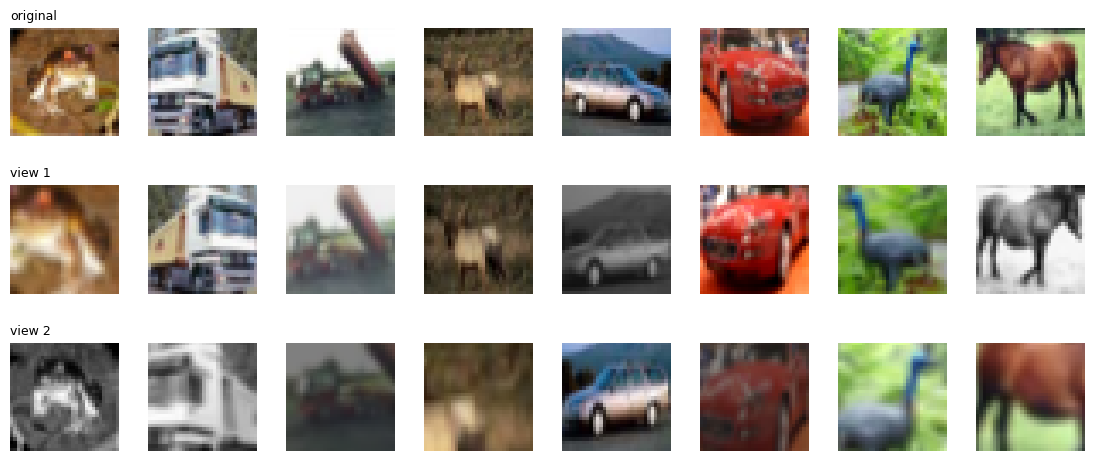

In [18]:
# Provided check: properties of color_jitter and random_grayscale.
torch.manual_seed(SEED)
x = data['x_val'][:4000]
for fn in [color_jitter, random_grayscale]:
    out = fn(x)
    assert out.shape == x.shape and out.min() >= 0 and out.max() <= 1
    assert torch.equal(fn(x, p=0.0), x)
assert torch.allclose(color_jitter(x, strength=0.0, p=1.0), x, atol=1e-6)

changed = lambda out: ((out - x).abs().flatten(1).max(dim=1).values > 1e-6).float().mean().item()
print('fraction jittered (p=0.5):', changed(color_jitter(x, p=0.5)))
assert abs(changed(color_jitter(x, p=0.5)) - 0.5) < 0.04
print('fraction grayscale (p=0.2):', changed(random_grayscale(x, p=0.2)))
assert abs(changed(random_grayscale(x, p=0.2)) - 0.2) < 0.03

gray_images = rgb_to_gray(x).expand(-1, 3, -1, -1)
jittered = color_jitter(gray_images, p=1.0)
assert torch.allclose(jittered[:, 0], jittered[:, 1], atol=1e-5) and torch.allclose(jittered[:, 1], jittered[:, 2], atol=1e-5)

constant = torch.full((2000, 3, 4, 4), 0.5, device=device)
ratio = color_jitter(constant, strength=0.4, p=1.0)[:, 0, 0, 0] / 0.5
print(f'brightness factors of a constant image: min {ratio.min().item():.3f}, max {ratio.max().item():.3f}')
assert ratio.min() >= 0.6 - 1e-5 and ratio.max() <= 1.4 + 1e-5 and ratio.std() > 0.15

grays = random_grayscale(x, p=1.0)
assert torch.allclose(grays[:, 0], grays[:, 1]) and torch.allclose(grays[:, 0:1], rgb_to_gray(x))
print('Augmentation check passed')

torch.manual_seed(SEED)
originals = data['x_train'][:8]
show_images([originals, augment(originals), augment(originals)], ['original', 'view 1', 'view 2'])
plt.show()


#### Question 2.2: Contrastive Loss [code] (12 points)

Implement the InfoNCE (NT-Xent) loss of SimCLR, first for a single anchor, then
with explicit loops, and finally vectorized.

**Lecture Connection**

> A positive pair contains two augmented views of the same instance  
> Negative candidates come from views of different instances  
> *(Lec07 Representation Learning, p. 29)*

> Two independently augmented views are generated for every example  
> Each view has one positive partner in the standard two-view setup  
> The remaining 2𝑁−2 views serve as negative candidates  
> *(Lec07 Representation Learning, p. 32)*

> The denominator includes all eligible candidates except the anchor itself  
> The final SimCLR objective averages losses over both directions of each positive pair  
> *(Lec07 Representation Learning, p. 34)*

> Matrix multiplication computes all pairwise similarities  
> Self-comparisons are excluded from the softmax  
> Cross-entropy selects the paired positive for every anchor  
> *(Lec07 Representation Learning, p. 38)*

> Positive probability is approximately 0.926  
> The resulting contrastive loss is approximately 0.077  
> *(Lec07 Representation Learning, p. 35)*

> Contrastive loss increases from approximately 0.077 to 0.493  
> *(Lec07 Representation Learning, p. 36)*

**Concept Connection**

For an anchor with cosine similarity $s^+$ to its positive and $s^-_1, \dots,
s^-_K$ to its negatives,

$$
\ell = -\log \frac{\exp(s^+/\tau)}{\exp(s^+/\tau) + \sum_{k=1}^{K} \exp(s^-_k/\tau)}
= \log \sum_{j} \exp(s_j/\tau) - s^+/\tau,
$$

where the last sum runs over the positive and all negatives. Computing it with
`torch.logsumexp` avoids overflow for small $\tau$. With the $2N$ views stacked
as $[z_1; z_2]$, the positive of view $i$ is view $(i + N) \bmod 2N$, and the
SimCLR loss is the mean of $\ell$ over all $2N$ anchors.

**Implementation Guide and Point Breakdown**

- **`anchor_loss` (2 points):** One anchor.
- **`cosine_similarity_matrix` (2 points):** Normalize the rows, then one matrix
  product.
- **`info_nce_loss_naive` (3 points):** Loops over anchors, calling
  `anchor_loss`.
- **`info_nce_loss` (5 points):** No loops; the target of anchor $i$ in
  `F.cross_entropy` is the column of its positive.

| Tensor | Shape |
|---|---|
| `z1`, `z2` | `(N, D)` |
| `[z1; z2]` and its similarity matrix | `(2N, D)`, `(2N, 2N)` |
| targets | `(2N,)` |

**Expected Check:** `anchor_loss` reproduces the numerical examples of the
lecture (losses of about `0.077` and `0.493`); the similarity matrix matches
`F.cosine_similarity`; the naive and vectorized losses agree to `1e-10`; and the
loss does not change when the embeddings are rescaled.


In [19]:
def anchor_loss(pos_sim, neg_sims, tau):
    """
    Inputs:
    - pos_sim: scalar tensor, similarity of the anchor to its positive
    - neg_sims: tensor of shape (K,), similarities of the anchor to its negatives
    - tau: temperature

    Returns:
    - loss: scalar tensor
    """
    ############################################################################
    # TODO 2.2 (2/12 points): Return the InfoNCE loss of one anchor from its   #
    # positive similarity and its negative similarities.                       #
    ############################################################################
    logits = torch.cat([pos_sim.reshape(1), neg_sims], dim=0) / tau
    loss = torch.logsumexp(logits, dim=0) - pos_sim / tau
    ############################################################################
    #                         END OF YOUR CODE                                 #
    ############################################################################
    return loss


def cosine_similarity_matrix(z):
    """Return the cosine similarities between all rows of z (M, D) as an (M, M) matrix."""
    ############################################################################
    # TODO 2.2 (2/12 points): Return the (M, M) matrix of cosine similarities  #
    # between all rows of z.                                                   #
    ############################################################################
    normalized = F.normalize(z, p=2, dim=1)
    sim = normalized @ normalized.T
    ############################################################################
    #                         END OF YOUR CODE                                 #
    ############################################################################
    return sim


def info_nce_loss_naive(z1, z2, tau=0.2):
    """InfoNCE loss of SimCLR for two views z1, z2 of shape (N, D), with loops."""
    ############################################################################
    # TODO 2.2 (3/12 points): Stack the 2N views as [z1; z2]. For every anchor #
    # i, its positive is the other view of the same image; every other view    #
    # except i itself is a negative. Average anchor_loss over all 2N anchors   #
    # using explicit Python loops.                                             #
    ############################################################################
    N = z1.shape[0]
    z = torch.cat([z1, z2], dim=0)
    sim = cosine_similarity_matrix(z)
    indices = torch.arange(2 * N, device=z.device)
    losses = []
    for i in range(2 * N):
        positive_index = (i + N) % (2 * N)
        negative_mask = (indices != i) & (indices != positive_index)
        pos_sim = sim[i, positive_index]
        neg_sims = sim[i, negative_mask]
        losses.append(anchor_loss(pos_sim, neg_sims, tau))
    loss = torch.stack(losses).mean()
    ############################################################################
    #                         END OF YOUR CODE                                 #
    ############################################################################
    return loss


def info_nce_loss(z1, z2, tau=0.2):
    """InfoNCE loss of SimCLR for two views z1, z2 of shape (N, D), without loops."""
    ############################################################################
    # TODO 2.2 (5/12 points): Compute the same loss without loops: divide the  #
    # similarity matrix of [z1; z2] by tau, exclude self-comparisons by        #
    # setting the diagonal to -inf, and use F.cross_entropy with the index of  #
    # each positive partner as the target.                                     #
    ############################################################################
    N = z1.shape[0]
    z = torch.cat([z1, z2], dim=0)
    logits = cosine_similarity_matrix(z) / tau
    self_mask = torch.eye(2 * N, device=z.device, dtype=torch.bool)
    logits = logits.masked_fill(self_mask, float('-inf'))
    targets = (torch.arange(2 * N, device=z.device) + N) % (2 * N)
    loss = F.cross_entropy(logits, targets)
    ############################################################################
    #                         END OF YOUR CODE                                 #
    ############################################################################
    return loss


In [20]:
# Provided check: the lecture examples, the similarity matrix, and naive vs. vectorized loss.
example = anchor_loss(torch.tensor(0.8), torch.tensor([0.2, 0.1]), tau=0.2)
harder = anchor_loss(torch.tensor(0.8), torch.tensor([0.7, 0.1]), tau=0.2)
print(f'lecture example: loss {example.item():.3f} (positive probability {math.exp(-example.item()):.3f}); '
      f'harder negative: loss {harder.item():.3f}')
assert abs(example.item() - 0.077) < 5e-4 and abs(harder.item() - 0.493) < 5e-4

torch.manual_seed(SEED)
z = torch.randn(12, 7, dtype=torch.float64)
expected = F.cosine_similarity(z[:, None, :], z[None, :, :], dim=2)
assert max_relative_error(cosine_similarity_matrix(z), expected) < 1e-10

z1, z2 = torch.randn(8, 5, dtype=torch.float64), torch.randn(8, 5, dtype=torch.float64)
for tau in [0.1, 0.5, 1.0]:
    naive, fast = info_nce_loss_naive(z1, z2, tau), info_nce_loss(z1, z2, tau)
    print(f'tau={tau}: naive {naive.item():.6f}, vectorized {fast.item():.6f}')
    assert abs(naive.item() - fast.item()) < 1e-10
assert abs(info_nce_loss(3 * z1, 0.5 * z2).item() - info_nce_loss(z1, z2).item()) < 1e-10

z1.requires_grad_()
info_nce_loss(z1, z2).backward()
assert torch.isfinite(z1.grad).all()
print('Contrastive loss check passed')


lecture example: loss 0.077 (positive probability 0.926); harder negative: loss 0.493
tau=0.1: naive 5.589792, vectorized 5.589792
tau=0.5: naive 2.626811, vectorized 2.626811
tau=1.0: naive 2.585212, vectorized 2.585212
Contrastive loss check passed


### Section 4: SimCLR Training


#### Question 2.3: SimCLR Training with Logging [code] (10 points)

Add a projection head to the shared encoder and complete a SimCLR training
loop that logs the loss together with the similarities of positive and
negative pairs.

**Lecture Connection**

> Two augmentations generate correlated views of the same image  
> The contrastive objective is applied to projected embeddings  
> The encoder output is reused for downstream learning  
> *(Lec07 Representation Learning, p. 37)*

**Concept Connection**

The **positive similarity** (`pos_sim`) and the **negative similarity**
(`neg_sim`) show what the loss is doing: a good run pulls the two views of an
image together (high `pos_sim`) while keeping views of different images apart
(`neg_sim` near 0). Logging them, together with the kNN accuracy of the encoder
after every epoch, reveals failures that the loss value alone can hide.

**Implementation Guide and Point Breakdown**

The provided code loops over mini-batches of training images, evaluates the
kNN accuracy of `model.encoder` after every epoch, and saves the log.
`loss_fn` is `info_nce_loss` with the chosen temperature, or another loss for
the experiment after this question.

- **Projection head (2 points):** `nn.Sequential` with the layers in the TODO.
- **Training iteration (5 points):** Two independent calls of `augment`.
- **Similarity statistics (3 points):** Use the normalized `z1` and `z2` of the
  current mini-batch; log `step`, `loss`, `pos_sim`, and `neg_sim`.

| Tensor | Shape |
|---|---|
| `h` (encoder output) | `(N, 256)` |
| `z1`, `z2` (projections) | `(N, 128)` |
| cross-view similarities | `(N, N)` |

**Expected Check:** The model returns `h` and `z` of the shapes above, and a
short run on 1,024 images logs the keys `step`, `loss`, `pos_sim`, `neg_sim`
per iteration and `epoch`, `knn_acc` per epoch, with `pos_sim` above `neg_sim`.


In [21]:
class SimCLR(nn.Module):
    def __init__(self, feature_dim=256, projection_dim=128):
        super().__init__()
        self.encoder = Encoder(feature_dim)
        ########################################################################
        # TODO 2.3 (2/10 points): Define self.projection_head as Linear(256,   #
        # 256) -> ReLU -> Linear(256, 128).                                    #
        ########################################################################
        self.projection_head = nn.Sequential(
            nn.Linear(feature_dim, feature_dim),
            nn.ReLU(),
            nn.Linear(feature_dim, projection_dim)
        )
        ########################################################################
        #                         END OF YOUR CODE                             #
        ########################################################################

    def forward(self, x):
        """Returns the representation h (N, 256) and the projection z (N, 128)."""
        h = self.encoder(x)
        return h, self.projection_head(h)


def train_simclr(model, name, loss_fn, num_epochs=15, lr=1e-3, batch_size=256, train_x=None):
    """
    Train model (a SimCLR network) with loss_fn(z1, z2) on two augmented views
    of every image, and log the training dynamics.

    Returns:
    - log: TrainingLog of the run (saved to logs/)
    """
    torch.manual_seed(SEED)
    train_x = data['x_train'] if train_x is None else train_x
    loader = TensorLoader(train_x, torch.zeros(len(train_x), device=train_x.device),
                          batch_size, shuffle=True)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-6)
    log = TrainingLog(name)
    step = 0

    for epoch in range(1, num_epochs + 1):
        model.train()
        for x, _ in loader:
            ####################################################################
            # TODO 2.3 (5/10 points): Create two views of x with augment,      #
            # compute their projections z1 and z2 with the model, compute the  #
            # loss with loss_fn(z1, z2), and update the model. Keep z1 and z2  #
            # for the statistics below.                                        #
            ####################################################################
            view1 = augment(x)
            view2 = augment(x)
            optimizer.zero_grad()
            _, z1 = model(view1)
            _, z2 = model(view2)
            loss = loss_fn(z1, z2)
            loss.backward()
            optimizer.step()
            ####################################################################
            #                         END OF YOUR CODE                         #
            ####################################################################

            ####################################################################
            # TODO 2.3 (3/10 points): Without gradient tracking, compute       #
            # pos_sim, the mean cosine similarity of the N positive pairs      #
            # (z1[i], z2[i]), and neg_sim, the mean cosine similarity of the N #
            # * (N - 1) pairs (z1[i], z2[j]) with i != j. Log one row with     #
            # log.log_step using the keys step, loss, pos_sim, and neg_sim.    #
            ####################################################################
            with torch.no_grad():
                z1_normalized = F.normalize(z1, p=2, dim=1)
                z2_normalized = F.normalize(z2, p=2, dim=1)
                similarities = z1_normalized @ z2_normalized.T
                N = z1.shape[0]
                pos_sim = similarities.diagonal().mean().item()
                negative_mask = ~torch.eye(N, device=z1.device, dtype=torch.bool)
                neg_sim = similarities[negative_mask].mean().item()
                log.log_step(step=step, loss=loss.item(), pos_sim=pos_sim, neg_sim=neg_sim)
            ####################################################################
            #                         END OF YOUR CODE                         #
            ####################################################################
            step += 1

        knn_acc = knn_accuracy(extract_features(model.encoder, bank_x), bank_y,
                               extract_features(model.encoder, data['x_val']), data['y_val'])
        log.log_epoch(epoch=epoch, knn_acc=knn_acc)
        print(f"[{name}] epoch {epoch:2d}/{num_epochs}: loss {log.steps['loss'][-1]:.3f}, "
              f"pos sim {log.steps['pos_sim'][-1]:.3f}, neg sim {log.steps['neg_sim'][-1]:.3f}, "
              f"kNN acc {knn_acc:.3f}")

    log.save()
    return log


In [22]:
# Provided check: model outputs and a short SimCLR run.
torch.manual_seed(SEED)
toy_model = SimCLR().to(device)
h, z = toy_model(data['x_val'][:4])
assert h.shape == (4, 256) and z.shape == (4, 128)
assert [type(layer).__name__ for layer in toy_model.projection_head] == ['Linear', 'ReLU', 'Linear']

check_log = train_simclr(toy_model, 'check_simclr', lambda z1, z2: info_nce_loss(z1, z2, tau=0.2),
                         num_epochs=2, train_x=data['x_train'][:1024])
reloaded = TrainingLog.load('check_simclr')
assert set(reloaded.steps) == {'step', 'loss', 'pos_sim', 'neg_sim'}, set(reloaded.steps)
assert set(reloaded.epochs) == {'epoch', 'knn_acc'}
assert len(reloaded.steps['loss']) == 2 * 4
assert reloaded.steps['pos_sim'][-1] > reloaded.steps['neg_sim'][-1]
print('train_simclr check passed')


[check_simclr] epoch  1/2: loss 5.478, pos sim 0.763, neg sim 0.475, kNN acc 0.341
[check_simclr] epoch  2/2: loss 5.343, pos sim 0.735, neg sim 0.363, kNN acc 0.347
train_simclr check passed


#### Provided: Representation Collapse

What happens if the loss only pulls the two views of each image together, with
no negatives? The cell below trains a fresh SimCLR model for 3 epochs with the
**alignment-only** loss $-\frac{1}{N}\sum_i s(z_{1,i}, z_{2,i})$ and logs it
exactly like a contrastive run.

**Lecture Connection**

> A matching-only objective may map every input to an identical vector  
> Collapsed embeddings cannot distinguish different examples  
> Contrastive negative candidates help prevent complete collapse  
> *(Lec07 Representation Learning, p. 31)*

**Expected Check:** At the end of the run, the negative similarity is above
`0.95`, so the projections of different images have become almost identical.


In [23]:
# Provided: alignment-only training, which collapses.
def alignment_loss(z1, z2):
    return -(F.normalize(z1, dim=1) * F.normalize(z2, dim=1)).sum(dim=1).mean()


torch.manual_seed(SEED)
collapse_log = train_simclr(SimCLR().to(device), 'alignment_only', alignment_loss, num_epochs=3)
print(f"final pos sim {collapse_log.steps['pos_sim'][-1]:.3f}, neg sim {collapse_log.steps['neg_sim'][-1]:.3f}")
assert collapse_log.steps['neg_sim'][-1] > 0.95


[alignment_only] epoch  1/3: loss -1.000, pos sim 1.000, neg sim 1.000, kNN acc 0.327
[alignment_only] epoch  2/3: loss -1.000, pos sim 1.000, neg sim 1.000, kNN acc 0.322
[alignment_only] epoch  3/3: loss -1.000, pos sim 1.000, neg sim 1.000, kNN acc 0.325
final pos sim 1.000, neg sim 1.000


#### Provided: Train SimCLR

The cell below trains SimCLR with your InfoNCE loss and temperature `0.2` for
15 epochs on the 45,000 training images (about 10 minutes on a Colab T4 GPU),
and plots its log next to the alignment-only run. You will interpret the curves
in Question 2.4.

**Lecture Connection**

> Batch size influences the number and diversity of negative candidates  
> Projection-head design and temperature influence training behavior  
> Downstream evaluation is needed to assess the final representation  
> *(Lec07 Representation Learning, p. 39)*

**Expected Check:** After the last epoch, the mean positive similarity of the
final 50 iterations exceeds the mean negative similarity by at least `0.5`, and
the kNN accuracy of the encoder is at least `0.5` and at least `0.15` higher than
that of the alignment-only run.


[simclr] epoch  1/15: loss 3.411, pos sim 0.695, neg sim 0.013, kNN acc 0.446
[simclr] epoch  2/15: loss 3.122, pos sim 0.727, neg sim 0.005, kNN acc 0.484
[simclr] epoch  3/15: loss 3.012, pos sim 0.741, neg sim 0.009, kNN acc 0.523
[simclr] epoch  4/15: loss 2.888, pos sim 0.752, neg sim 0.003, kNN acc 0.539
[simclr] epoch  5/15: loss 2.906, pos sim 0.748, neg sim 0.002, kNN acc 0.556
[simclr] epoch  6/15: loss 2.725, pos sim 0.778, neg sim 0.001, kNN acc 0.567
[simclr] epoch  7/15: loss 2.705, pos sim 0.785, neg sim 0.003, kNN acc 0.578
[simclr] epoch  8/15: loss 2.733, pos sim 0.775, neg sim 0.004, kNN acc 0.584
[simclr] epoch  9/15: loss 2.768, pos sim 0.765, neg sim 0.005, kNN acc 0.595
[simclr] epoch 10/15: loss 2.669, pos sim 0.782, neg sim 0.001, kNN acc 0.599
[simclr] epoch 11/15: loss 2.743, pos sim 0.766, neg sim 0.002, kNN acc 0.605
[simclr] epoch 12/15: loss 2.711, pos sim 0.770, neg sim 0.004, kNN acc 0.614
[simclr] epoch 13/15: loss 2.663, pos sim 0.778, neg sim -0.000,

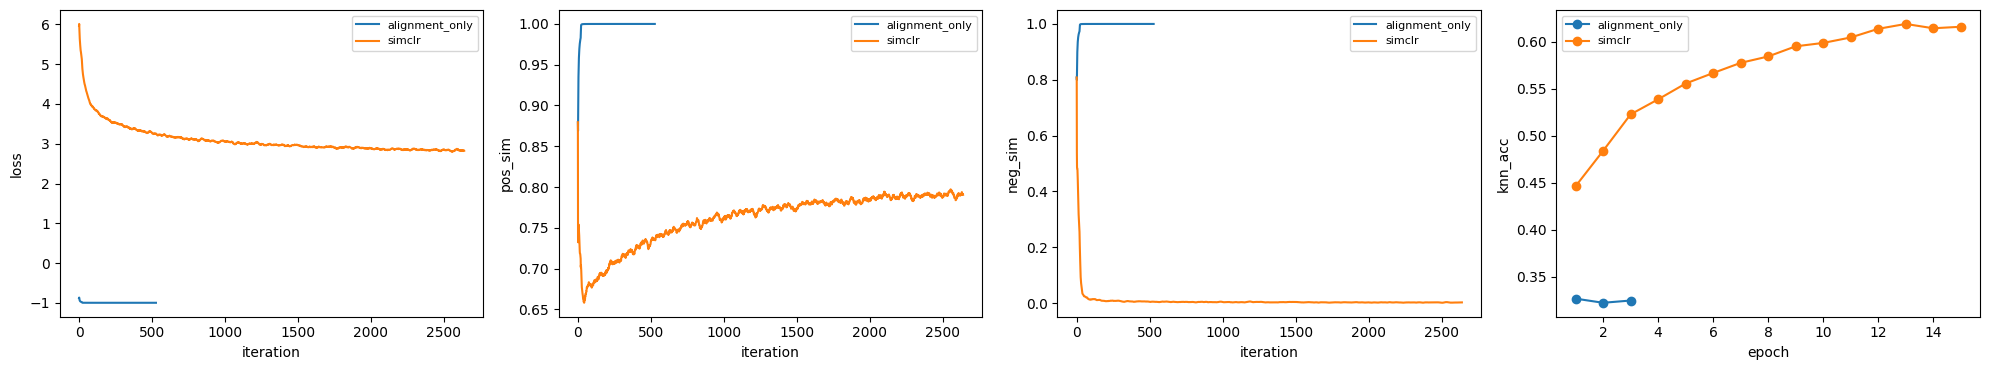

In [24]:
# Provided: SimCLR with the InfoNCE loss.
torch.manual_seed(SEED)
simclr = SimCLR().to(device)
simclr_log = train_simclr(simclr, 'simclr', lambda z1, z2: info_nce_loss(z1, z2, tau=0.2), num_epochs=15)

plot_logs([collapse_log, simclr_log], step_keys=['loss', 'pos_sim', 'neg_sim'], epoch_keys=['knn_acc'])
plt.show()


In [25]:
# Provided check: SimCLR separates positives from negatives and learns useful features.
pos = np.mean(simclr_log.steps['pos_sim'][-50:])
neg = np.mean(simclr_log.steps['neg_sim'][-50:])
print(f'last 50 iterations: pos sim {pos:.3f}, neg sim {neg:.3f}')
print(f"kNN acc: simclr {simclr_log.epochs['knn_acc'][-1]:.3f}, alignment only {collapse_log.epochs['knn_acc'][-1]:.3f}")
assert pos - neg >= 0.5
assert simclr_log.epochs['knn_acc'][-1] >= 0.5
assert simclr_log.epochs['knn_acc'][-1] >= collapse_log.epochs['knn_acc'][-1] + 0.15
print('SimCLR training check passed')


last 50 iterations: pos sim 0.791, neg sim 0.002
kNN acc: simclr 0.616, alignment only 0.325
SimCLR training check passed


#### Provided: Temperature

The cell below trains two more SimCLR models for 4 epochs each, with
temperatures `0.05` and `1.0`, and plots their logs next to the first epochs of
the run with temperature `0.2`. Everything else is identical. You will compare
the three runs in Question 2.4.

**Lecture Connection**

> Smaller temperatures produce sharper softmax probabilities  
> Larger temperatures produce smoother softmax probabilities  
> Temperature changes the weighting of competing candidates  
> *(Lec07 Representation Learning, p. 33)*


[simclr_tau_0.05] epoch  1/4: loss 2.249, pos sim 0.803, neg sim 0.308, kNN acc 0.471
[simclr_tau_0.05] epoch  2/4: loss 1.521, pos sim 0.778, neg sim 0.198, kNN acc 0.516
[simclr_tau_0.05] epoch  3/4: loss 1.172, pos sim 0.766, neg sim 0.087, kNN acc 0.547
[simclr_tau_0.05] epoch  4/4: loss 1.047, pos sim 0.763, neg sim 0.105, kNN acc 0.555
[simclr_tau_1] epoch  1/4: loss 5.298, pos sim 0.780, neg sim 0.001, kNN acc 0.413
[simclr_tau_1] epoch  2/4: loss 5.283, pos sim 0.789, neg sim 0.000, kNN acc 0.446
[simclr_tau_1] epoch  3/4: loss 5.269, pos sim 0.801, neg sim 0.001, kNN acc 0.491
[simclr_tau_1] epoch  4/4: loss 5.237, pos sim 0.830, neg sim 0.000, kNN acc 0.510


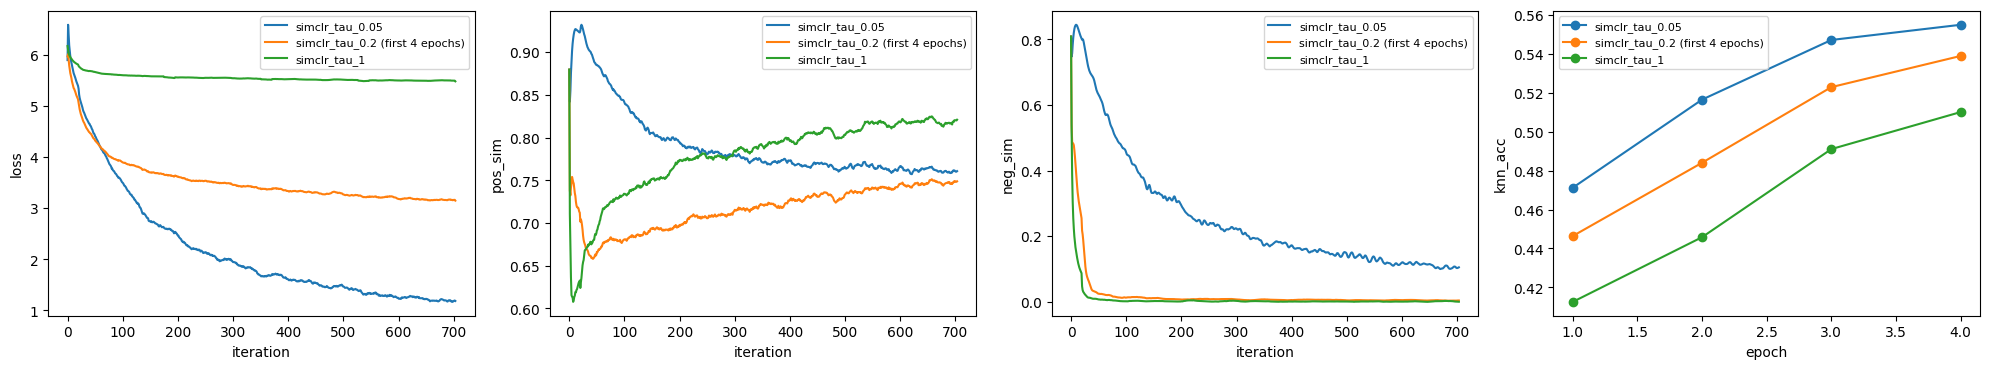

In [26]:
# Provided: SimCLR with a smaller and a larger temperature.
temperature_logs = []
for tau in [0.05, 1.0]:
    torch.manual_seed(SEED)
    temperature_logs.append(train_simclr(SimCLR().to(device), f'simclr_tau_{tau:g}',
                                         lambda z1, z2, tau=tau: info_nce_loss(z1, z2, tau=tau),
                                         num_epochs=4))

first_epochs = TrainingLog('simclr_tau_0.2 (first 4 epochs)')
steps_per_epoch = len(simclr_log.steps['step']) // 15
for key, values in simclr_log.steps.items():
    first_epochs.steps[key] = values[:4 * steps_per_epoch]
for key, values in simclr_log.epochs.items():
    first_epochs.epochs[key] = values[:4]
plot_logs([temperature_logs[0], first_epochs, temperature_logs[1]],
          step_keys=['loss', 'pos_sim', 'neg_sim'], epoch_keys=['knn_acc'])
plt.show()


#### Question 2.4: Reading Contrastive Training Curves [written] (6 points)

---

Answer using the logs of the alignment-only run and the SimCLR runs (2 points
each):

1. Describe the `pos_sim`, `neg_sim`, and `knn_acc` curves of the
   alignment-only run. What happened to the projections, and why does the
   alignment-only objective allow it?
2. Describe the same curves for the SimCLR run with temperature `0.2`. How do
   the negatives in the InfoNCE loss prevent the failure of the alignment-only
   run? Why is the loss value alone not enough to tell whether the
   representation is improving?
3. Compare the runs with temperatures `0.05`, `0.2`, and `1.0` over their first
   four epochs: their `pos_sim`, `neg_sim`, and `knn_acc`. Explain the
   differences with how the temperature weights the negatives in the loss.

$\color{blue}{\textit Your Answer:}$

<!-- ANSWER_START: 2.4 -->

*Fill this in*

1.Alignment-only 학습에서는 첫 epoch부터 pos_sim과 neg_sim이 모두 출력상 1.000에 도달했고, 이후에도 유지되었다. 반면 knn_acc는 0.327 → 0.322 → 0.325로, 뚜렷한 개선이 나타나지 않았다. 이는 같은 이미지의 두 view뿐 아니라 서로 다른 이미지의 projection까지 거의 같은 방향으로 정렬되는 표현 붕괴가 발생했음을 의미한다. Alignment-only 목적함수는 긍정적 쌍의 코사인 유사도를 높이는 것만 요구하고, 서로 다른 이미지의 projection을 구분하도록 하는 항은 없다. 따라서 모든 입력을 같은 방향의 벡터로 보내도 손실을 최소화할 수 있다. 실제로 손실은 출력상 −1.000에 도달했지만, 이것이 유용한 표현을 학습했다는 뜻은 아니다. 또한 pos_sim과 neg_sim은 projection z 에서 계산하지만, kNN 정확도는 projection head 이전의 인코더 표현 h 로 평가한다. 따라서 projection이 붕괴했더라도 인코더 표현에는 이미지 구분 정보가 일부 남아 있어, kNN 정확도가 무작위 분류 수준까지 떨어지지 않을 수 있다.

2.Temperature가 0.2인 SimCLR에서는 epoch 마지막 배치 기준 pos_sim이 첫 epoch의 0.695에서 마지막 epoch의 0.784로 전반적으로 증가했고, neg_sim은 0.013에서 0.002로 낮아져 0 근처를 유지했다. 인코더의 knn_acc는 0.446에서 0.616으로 증가했다. 마지막 50 iteration의 평균도 pos_sim은 0.791, neg_sim은 0.002로 큰 차이를 보였다. 이는 긍정적 쌍은 비슷하게 만들면서도 서로 다른 이미지들을 모두 같은 방향으로 보내는 붕괴는 피했음을 보여준다. InfoNCE는 positive뿐 아니라 negative도 분모에 포함한다. Negative의 유사도가 높으면 positive를 선택할 확률이 낮아지므로, 모델은 positive를 가깝게 만드는 동시에 혼동되는 negative와 구별해야 한다. 따라서 모든 projection이 같은 방향이 되는 것은 InfoNCE를 최소화하는 좋은 해법이 아니다. 손실값만으로 표현의 개선을 판단할 수 없는 이유는 학습 목적과 다운스트림 분류 성능이 완전히 같지 않기 때문이다. Alignment-only에서는 손실이 −1까지 낮아졌지만 projection이 붕괴했다. SimCLR에서도 손실은 projection z에서 계산하고 kNN은 인코더 표현 h에서 평가하므로, 손실 감소가 분류 성능 향상을 항상 보장하지는 않는다. 따라서 손실과 함께 positive,negative 유사도 및 kNN 정확도를 확인해야 한다. 서로 다른 목적함수나 temperature 사이의 손실 절댓값도 그대로 성능 순위로 해석하면 안 된다.

3. 처음 4 epoch를 비교하면, temperature가 0.05일 때 pos_sim은 0.803에서 0.763으로 감소했고, neg_sim도 0.308에서 0.105로 감소했다. 반면 knn_acc는 0.471에서 0.555로 증가하여, 세 설정 중 4번째 epoch에서 가장 높은 분류 정확도를 보였다. Temperature가 0.2일 때는 pos_sim이 0.695에서 0.752로 증가했고, neg_sim은 0.013에서 0.003으로 낮아져 0 근처를 유지했다. knn_acc는 0.446에서 0.539로 증가하여, 0.05와 1.0 사이의 성능을 보였다. Temperature가 1.0일 때는 pos_sim이 0.780에서 0.830으로 증가했고, neg_sim은 0.001에서 출력상 0.000으로 낮아졌다. 하지만 knn_acc는 0.413에서 0.510으로 증가하는 데 그쳐, 세 설정 중 4번째 epoch에서 가장 낮았다. 따라서 이번 실험에서는 positive 유사도가 가장 높고 평균 negative 유사도가 가장 낮은 설정이 반드시 가장 높은 kNN 정확도를 보이지는 않았다. InfoNCE에서 각 후보의 가중치는 $\exp(s/\tau)$에 영향을 받는다. 작은 temperature는 유사도 차이를 확대하여, anchor와 유사도가 높은 hard negative에 가중치를 더 집중시킨다. 반면 큰 temperature는 확률 분포를 부드럽게 하여 negative 사이의 가중치 차이를 줄인다. 따라서 평균 negative 유사도가 같더라도, 어떤 negative에 학습이 집중되는지는 달라질 수 있다. 작은 temperature가 반드시 평균 negative 유사도를 가장 낮게 만드는 것은 아니다.

<!-- ANSWER_END: 2.4 -->

---


### Section 5: Comparing Representations


#### Question 2.5: Label Efficiency [code] (6 points)

Measure how well each representation performs when only a small fraction of
the training labels is available for the linear probe.

**Lecture Connection**

> Human labeling can be costly and difficult to scale  
> The resulting encoder can support future supervised tasks  
> *(Lec07 Representation Learning, p. 20)*

> Extract features from the corresponding pretrained encoders  
> Train linear classifiers using the same labeled data protocol  
> Compare downstream accuracy under consistent evaluation conditions  
> *(Lec07 Representation Learning, p. 45)*

> Exclude test labels from model selection and training decisions  
> *(Lec07 Representation Learning, p. 46)*

**Implementation Guide and Point Breakdown**

- **`balanced_subset` (2 points):** For example, with `per_class=45` the subset
  contains the first 45 examples of each of the 10 classes (450 indices),
  sorted.
- **`label_efficiency` (4 points):** Smaller subsets have fewer iterations per
  epoch, so they are trained for more epochs: with `base_epochs=30`, the 1%,
  10%, and 100% probes train for 300, 95, and 30 epochs. Use your
  `linear_probe`; the validation and test sets stay the same for every
  fraction.

| Fraction of labels | Examples per class | Labeled examples |
|---|---:|---:|
| 1% | 45 | 450 |
| 10% | 450 | 4,500 |
| 100% | all | 45,000 (all training examples) |

The classes are not exactly balanced in the 45,000 training images (between
4,470 and 4,551 per class), so the 100% probe simply uses every training
example and matches the linear probe of `evaluate_features`.

**Expected Check:** `balanced_subset` returns the expected indices on a small
example, and `label_efficiency` returns one test accuracy per fraction, with
more labels giving a higher accuracy for the hand-crafted features.


In [27]:
def balanced_subset(labels, per_class, num_classes=10):
    """
    Inputs:
    - labels: tensor of shape (N,)
    - per_class: number of examples to keep from every class

    Returns:
    - indices: sorted LongTensor of shape (num_classes * per_class,)
    """
    ############################################################################
    # TODO 2.5 (2/6 points): Return a LongTensor with the indices of the first #
    # per_class examples of every class, in increasing index order.            #
    ############################################################################
    class_indices = []
    for class_index in range(num_classes):
        selected = torch.nonzero(labels == class_index, as_tuple=True)[0][:per_class]
        class_indices.append(selected)
    indices = torch.cat(class_indices).sort().values
    ############################################################################
    #                         END OF YOUR CODE                                 #
    ############################################################################
    return indices


def label_efficiency(name, train_feats, train_labels, val_feats, val_labels, test_feats,
                     test_labels, fractions=(0.01, 0.1, 1.0), base_epochs=30, num_classes=10):
    """
    Returns:
    - results: dict mapping each fraction to the test accuracy of a linear probe
      trained on a class-balanced subset with that fraction of the labels
    """
    results = {}
    ############################################################################
    # TODO 2.5 (4/6 points): For every fraction, select a class-balanced       #
    # subset with round(fraction * len(train_labels) / num_classes) examples   #
    # per class (or all training examples if fraction is 1), train a linear    #
    # probe on it for round(base_epochs / sqrt(fraction)) epochs with the name #
    # f"{name}_labels_{fraction:g}", and store the returned test accuracy in   #
    # results[fraction].                                                       #
    ############################################################################
    for fraction in fractions:
        if fraction == 1:
            subset_feats = train_feats
            subset_labels = train_labels
        else:
            per_class = round(fraction * len(train_labels) / num_classes)
            indices = balanced_subset(train_labels, per_class, num_classes=num_classes)
            subset_feats = train_feats[indices]
            subset_labels = train_labels[indices]
        num_epochs = round(base_epochs / math.sqrt(fraction))
        _, test_acc = linear_probe(
            subset_feats, subset_labels, val_feats, val_labels, test_feats, test_labels,
            name=f"{name}_labels_{fraction:g}", num_epochs=num_epochs, num_classes=num_classes
        )
        results[fraction] = test_acc
    ############################################################################
    #                         END OF YOUR CODE                                 #
    ############################################################################
    return results


In [28]:
# Provided check: balanced_subset and label_efficiency.
toy_labels = torch.tensor([2, 0, 1, 0, 2, 1, 1, 0, 2, 2])
assert balanced_subset(toy_labels, 2, num_classes=3).tolist() == [0, 1, 2, 3, 4, 5]
assert balanced_subset(toy_labels, 1, num_classes=3).tolist() == [0, 1, 2]
subset = balanced_subset(data['y_train'], 45)
assert len(subset) == 450 and torch.equal(torch.bincount(data['y_train'][subset]), torch.full((10,), 45, device=device))

hc = results['hand_crafted']['feats']
hc_efficiency = label_efficiency('hand_crafted', hc['train'], data['y_train'], hc['val'], data['y_val'],
                                 hc['test'], data['y_test'])
print('hand-crafted features:', {f'{k:.0%}': round(v, 3) for k, v in hc_efficiency.items()})
assert set(hc_efficiency) == {0.01, 0.1, 1.0}
assert hc_efficiency[0.01] < hc_efficiency[0.1] < hc_efficiency[1.0]
print('label_efficiency check passed')


hand-crafted features: {'1%': 0.388, '10%': 0.512, '100%': 0.547}
label_efficiency check passed


#### Question 2.6: Fine-Tuning [code] (6 points)

A linear probe keeps the encoder frozen. Fine-tuning instead trains the
encoder together with a new classification head on the labeled data. Complete
a training loop that trains the whole network with labels; the same function
also trains an encoder from scratch.

**Lecture Connection**

> Linear probing trains only the downstream prediction head  
> Full fine-tuning updates the encoder and prediction head  
> Fine-tuning allows representations to adapt to the downstream objective  
> Fine-tuning can require more computation and careful regularization  
> *(Lec07 Representation Learning, p. 44)*

**Concept Connection**

Fine-tuning starts from the pretrained weights and updates all of them. When an
encoder is trained from its random initialization with the same loop, the
result is ordinary supervised training. Comparing the two with the same labels
shows how much the pretrained starting point helps. Random crops and flips of
the labeled images serve as data augmentation.

**Implementation Guide and Point Breakdown**

The provided code builds the network `nn.Sequential(encoder, nn.Linear(256, 10))`,
the Adam optimizer over all of its parameters, and a loader over the labeled
subset `train_idx`; it keeps the network from the epoch with the best
validation accuracy and evaluates it on the test set.

- **Training iteration (4 points):** Apply `random_resized_crop_flip` to the
  mini-batch, compute `F.cross_entropy`, update every parameter, and log `step`
  and `loss`.
- **Epoch evaluation (2 points):** Compute the validation accuracy with your
  `extract_features` (it puts the network in evaluation mode and returns the
  logits) and log `epoch` and `val_acc`.

| Tensor | Shape |
|---|---|
| mini-batch `x` | `(N, 3, 32, 32)` |
| logits | `(N, 10)` |

**Expected Check:** A short run on 512 images logs the keys above, changes the
encoder's weights (unlike a linear probe), and lowers the training loss.


In [29]:
def train_classifier(encoder, name, train_idx, num_epochs=30, lr=1e-3, batch_size=256):
    """
    Train encoder and a new linear head end to end on the labeled examples train_idx.

    Returns:
    - log: TrainingLog of the run (saved to logs/)
    - test_acc: test accuracy of the network from the epoch with the best
      validation accuracy (Python float)
    """
    torch.manual_seed(SEED)
    model = nn.Sequential(encoder, nn.Linear(256, 10)).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=5e-4)
    loader = TensorLoader(data['x_train'][train_idx], data['y_train'][train_idx], batch_size, shuffle=True)
    log = TrainingLog(name)
    step = 0
    best_val_acc, best_state = -1.0, None

    for epoch in range(1, num_epochs + 1):
        model.train()
        for x, y in loader:
            ####################################################################
            # TODO 2.6 (4/6 points): Apply random_resized_crop_flip to x,      #
            # compute the cross-entropy loss of the model, update all          #
            # parameters, and log one row with log.log_step using the keys     #
            # step and loss.                                                   #
            ####################################################################
            x_augmented = random_resized_crop_flip(x)
            optimizer.zero_grad()
            logits = model(x_augmented)
            loss = F.cross_entropy(logits, y)
            loss.backward()
            optimizer.step()
            log.log_step(step=step, loss=loss.item())
            ####################################################################
            #                         END OF YOUR CODE                         #
            ####################################################################
            step += 1

        ########################################################################
        # TODO 2.6 (2/6 points): Compute the validation accuracy of the model  #
        # with extract_features and log one row with log.log_epoch using the   #
        # keys epoch and val_acc.                                              #
        ########################################################################
        val_logits = extract_features(model, data['x_val'])
        val_acc = (val_logits.argmax(dim=1) == data['y_val']).float().mean().item()
        log.log_epoch(epoch=epoch, val_acc=val_acc)
        ########################################################################
        #                         END OF YOUR CODE                             #
        ########################################################################

        if log.epochs['val_acc'][-1] > best_val_acc:
            best_val_acc = log.epochs['val_acc'][-1]
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    test_acc = (extract_features(model, data['x_test']).argmax(dim=1) == data['y_test']).float().mean().item()
    print(f'[{name}] best val acc {best_val_acc:.3f}, test acc {test_acc:.3f}')
    log.save()
    return log, test_acc


In [30]:
# Provided check: a short fine-tuning run updates the encoder.
torch.manual_seed(SEED)
toy_encoder = Encoder().to(device)
before = [p.detach().clone() for p in toy_encoder.parameters()]
check_log, _ = train_classifier(toy_encoder, 'check_classifier', torch.arange(512, device=device), num_epochs=3)
reloaded = TrainingLog.load('check_classifier')
assert set(reloaded.steps) == {'step', 'loss'} and set(reloaded.epochs) == {'epoch', 'val_acc'}
assert len(reloaded.steps['loss']) == 3 * 2
assert any(not torch.equal(b, p) for b, p in zip(before, toy_encoder.parameters())), 'the encoder was not updated'
assert np.mean(reloaded.steps['loss'][-2:]) < np.mean(reloaded.steps['loss'][:2])
print('train_classifier check passed')


[check_classifier] best val acc 0.192, test acc 0.185
train_classifier check passed


#### Provided: Fine-Tuning, Training from Scratch, and a Supervised Encoder

The cell below uses 10% of the labels (450 per class) to train the shared
encoder in two ways: fine-tuning a copy of the SimCLR encoder, and training a
randomly initialized encoder from scratch. Both use your `train_classifier`
for 30 epochs. It then trains a **supervised encoder** from scratch with all
45,000 labels for 10 epochs; this encoder sees every label during training, so
it is a reference for how good a representation of this encoder can become
with full supervision, not a fair competitor. The supervised encoder is added
to the comparison below.

**Lecture Connection**

> Supervised learning uses externally provided target labels  
> Self-supervised learning constructs training signals from the data itself  
> The training signal determines what the network is encouraged to learn  
> *(Lec07 Representation Learning, p. 10)*

> Supervised prediction minimizes errors against provided targets  
> Different objectives can produce different feature properties  
> *(Lec07 Representation Learning, p. 11)*

**Expected Check:** With 10% of the labels, fine-tuning the SimCLR encoder
reaches a test accuracy at least `0.02` higher than training the same encoder
from scratch.


[scratch_labels_0.1] best val acc 0.636, test acc 0.621
[finetune_simclr_labels_0.1] best val acc 0.703, test acc 0.692
[supervised_all_labels] best val acc 0.707, test acc 0.699


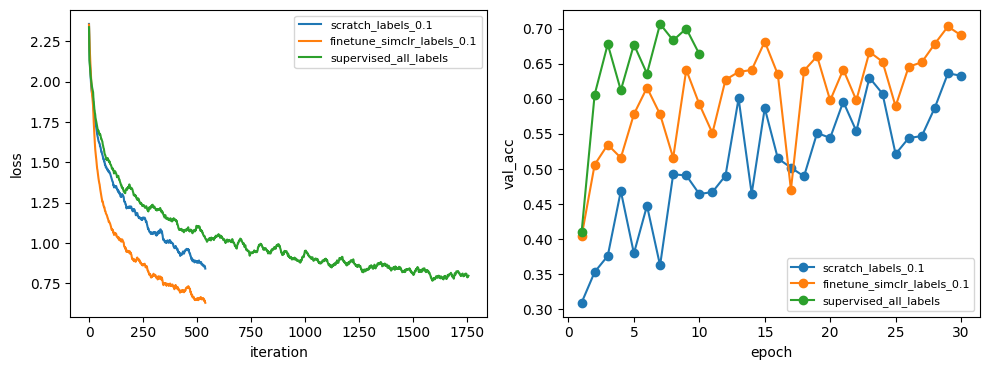

In [31]:
# Provided: fine-tuning versus training from scratch with 10% of the labels, and a supervised encoder.
subset_10 = balanced_subset(data['y_train'], 450)

torch.manual_seed(SEED)
scratch_log, scratch_acc = train_classifier(Encoder(), 'scratch_labels_0.1', subset_10)
finetune_log, finetune_acc = train_classifier(copy.deepcopy(simclr.encoder), 'finetune_simclr_labels_0.1',
                                              subset_10)

torch.manual_seed(SEED)
supervised_encoder = Encoder()
supervised_log, supervised_acc = train_classifier(supervised_encoder, 'supervised_all_labels',
                                                  torch.arange(len(data['y_train']), device=device),
                                                  num_epochs=10)

plot_logs([scratch_log, finetune_log, supervised_log], step_keys=['loss'], epoch_keys=['val_acc'])
plt.show()


In [32]:
# Provided check: fine-tuning the SimCLR encoder beats training it from scratch.
print(f'10% of the labels: from scratch {scratch_acc:.3f}, fine-tuned SimCLR {finetune_acc:.3f}')
assert finetune_acc >= scratch_acc + 0.02
print('Fine-tuning check passed')


10% of the labels: from scratch 0.621, fine-tuned SimCLR 0.692
Fine-tuning check passed


#### Provided: Comparison of All Representations

The cell below evaluates the learned encoders exactly like the baselines and
measures the label efficiency of every representation. It also measures how
**invariant** each representation is to the augmentations: for 2,000 validation
images, `view_sim_same` is the mean cosine similarity between the features of
two augmented views of the same image, and `view_sim_diff` is the mean
similarity between views of different images. It prints one table, saves it to
`logs/representation_comparison.csv`, and plots the linear-probe accuracy
against the fraction of labels. The 10% fine-tuning results are printed below
the table.

**Lecture Connection**

> Invariance reduces sensitivity to selected input transformations  
> Discriminability helps distinguish meaningfully different examples  
> *(Lec07 Representation Learning, p. 8)*

> An invariant representation is insensitive to chosen transformations  
> Different augmented inputs can map to similar representations  
> The desired invariance depends on the downstream task  
> *(Lec07 Representation Learning, p. 24)*

> Match encoder capacity and downstream evaluation conditions where feasible  
> *(Lec07 Representation Learning, p. 46)*

**Expected Check:** Among the representations learned without labels and the
baselines, SimCLR has the highest kNN accuracy and the highest linear-probe
accuracy at every fraction of labels, and the gap between `view_sim_same` and
`view_sim_diff` is larger for SimCLR than for raw pixels.


autoencoder      dim   256: kNN 0.489, linear probe 0.527
denoising_autoencoder dim   256: kNN 0.494, linear probe 0.532
simclr           dim   256: kNN 0.650, linear probe 0.696
supervised       dim   256: kNN 0.764, linear probe 0.792
representation           dim    knn  linear_1%  linear_10%  linear_100%  view_sim_same  view_sim_diff
raw_pixels              3072  0.350      0.293       0.357        0.383          0.891          0.836
hand_crafted             208  0.472      0.388       0.512        0.547          0.672          0.482
random_encoder           256  0.432      0.353       0.468        0.507          0.957          0.927
autoencoder              256  0.489      0.346       0.477        0.527          0.886          0.823
denoising_autoencoder    256  0.494      0.368       0.484        0.532          0.912          0.846
simclr                   256  0.650      0.558       0.665        0.696          0.882          0.586
supervised               256  0.764      0.752   

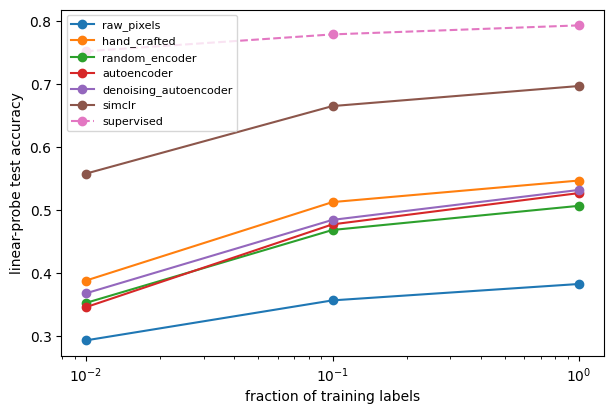

In [33]:
# Provided: evaluate the learned encoders and compare all representations.
results['autoencoder'] = evaluate_features('autoencoder', autoencoder.encoder)
results['denoising_autoencoder'] = evaluate_features('denoising_autoencoder', denoising_autoencoder.encoder)
results['simclr'] = evaluate_features('simclr', simclr.encoder)
results['supervised'] = evaluate_features('supervised', supervised_encoder)

feature_fns = {
    'raw_pixels': lambda x: x.flatten(1), 'hand_crafted': handcrafted_features,
    'random_encoder': random_encoder, 'autoencoder': autoencoder.encoder,
    'denoising_autoencoder': denoising_autoencoder.encoder, 'simclr': simclr.encoder,
    'supervised': supervised_encoder,
}


@torch.no_grad()
def view_similarity(feature_fn, x):
    """Mean cosine similarity of two augmented views of the same image and of different images."""
    torch.manual_seed(SEED)
    a = F.normalize(extract_features(feature_fn, augment(x)), dim=1)
    b = F.normalize(extract_features(feature_fn, augment(x)), dim=1)
    sim = a @ b.T
    n = len(x)
    return sim.diagonal().mean().item(), ((sim.sum() - sim.diagonal().sum()) / (n * (n - 1))).item()


for name, result in results.items():
    feats = result['feats']
    result['efficiency'] = (hc_efficiency if name == 'hand_crafted' else
                            label_efficiency(name, feats['train'], data['y_train'], feats['val'],
                                             data['y_val'], feats['test'], data['y_test']))
    result['view_sim'] = view_similarity(feature_fns[name], data['x_val'][:2000])

header = ['representation', 'dim', 'knn', 'linear_1%', 'linear_10%', 'linear_100%',
          'view_sim_same', 'view_sim_diff']
rows = [[name, result['feats']['train'].shape[1], result['knn']]
        + [result['efficiency'][f] for f in (0.01, 0.1, 1.0)] + list(result['view_sim'])
        for name, result in results.items()]
print(f"{header[0]:22s} {header[1]:>5s} {header[2]:>6s} {header[3]:>10s} {header[4]:>11s} "
      f"{header[5]:>12s} {header[6]:>14s} {header[7]:>14s}")
for row in rows:
    print(f'{row[0]:22s} {row[1]:5d} {row[2]:6.3f} {row[3]:10.3f} {row[4]:11.3f} {row[5]:12.3f} '
          f'{row[6]:14.3f} {row[7]:14.3f}')
print('(the supervised encoder was trained with all 45,000 labels, so it is a reference, not a competitor)')
print(f"\n10% of the labels: linear probe on SimCLR {results['simclr']['efficiency'][0.1]:.3f}, "
      f"fine-tuned SimCLR {finetune_acc:.3f}, trained from scratch {scratch_acc:.3f}")
with open('logs/representation_comparison.csv', 'w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(header)
    writer.writerows(rows)

fig, ax = plt.subplots(figsize=(7, 4.5))
for i, (name, result) in enumerate(results.items()):
    fractions = sorted(result['efficiency'])
    style = 'o--' if name == 'supervised' else 'o-'
    ax.plot(fractions, [result['efficiency'][f] for f in fractions], style, color=f'C{i}', label=name)
ax.set_xscale('log')
ax.set_xlabel('fraction of training labels')
ax.set_ylabel('linear-probe test accuracy')
ax.legend(fontsize=8)
plt.show()


In [34]:
# Provided check: SimCLR is the best representation learned without labels, and it is invariant to its augmentations.
label_free = [row for row in rows if row[0] != 'supervised']
for column in range(2, 6):
    best = max(label_free, key=lambda row: row[column])
    assert best[0] == 'simclr', (header[column], best[0])
gap = {row[0]: row[6] - row[7] for row in rows}
print('view_sim_same - view_sim_diff:', {name: round(value, 3) for name, value in gap.items()})
assert gap['simclr'] > gap['raw_pixels']
print('Comparison check passed')


view_sim_same - view_sim_diff: {'raw_pixels': 0.054, 'hand_crafted': 0.19, 'random_encoder': 0.03, 'autoencoder': 0.063, 'denoising_autoencoder': 0.066, 'simclr': 0.296, 'supervised': 0.277}
Comparison check passed


#### Provided: Nearest Neighbors in Pixel Space and Feature Space

The cell below retrieves, for every test image, the five most similar training
images by cosine similarity of the features, and prints the fraction of them
that share the query's class (precision@5) for every representation. It then
shows the neighbors in pixel space and in SimCLR feature space for the first
test image of five classes; each row title counts how many of the five
neighbors share the query's class.

**Lecture Connection**

> Semantically similar images may look different at the pixel level  
> Learned features can organize data according to more meaningful relationships  
> *(Lec07 Representation Learning, p. 5)*

> Inspect errors and feature visualizations alongside quantitative metrics  
> *(Lec07 Representation Learning, p. 46)*


raw_pixels             precision@5 0.312
hand_crafted           precision@5 0.370
random_encoder         precision@5 0.337
autoencoder            precision@5 0.397
denoising_autoencoder  precision@5 0.395
simclr                 precision@5 0.549
supervised             precision@5 0.697


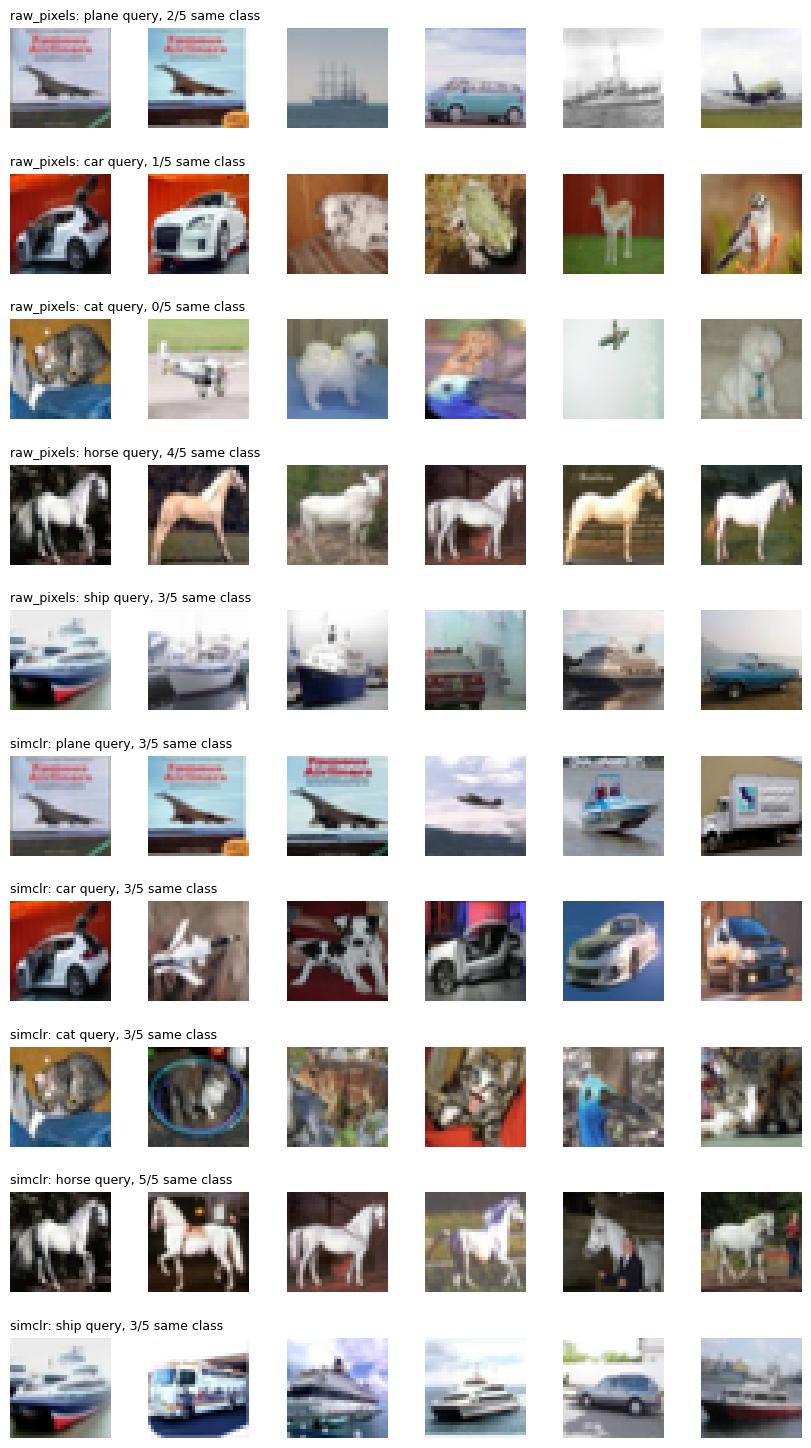

In [35]:
# Provided: nearest training images of test queries in pixel space and feature space.
@torch.no_grad()
def nearest_neighbors(name, query_feats, k=5):
    bank = F.normalize(results[name]['feats']['train'], dim=1)
    return (F.normalize(query_feats, dim=1) @ bank.T).topk(k, dim=1).indices


for name in results:
    same = sum((data['y_train'][nearest_neighbors(name, results[name]['feats']['test'][start:start + 1000])]
                == data['y_test'][start:start + 1000, None]).sum().item()
               for start in range(0, len(data['y_test']), 1000))
    print(f'{name:22s} precision@5 {same / (5 * len(data["y_test"])):.3f}')

query_ids = [torch.nonzero(data['y_test'] == c).flatten()[0].item() for c in [0, 1, 3, 7, 8]]
row_images, row_titles = [], []
for name in ['raw_pixels', 'simclr']:
    neighbors = nearest_neighbors(name, results[name]['feats']['test'][query_ids])
    for q, nn_ids in zip(query_ids, neighbors):
        same = (data['y_train'][nn_ids] == data['y_test'][q]).sum().item()
        row_images.append(torch.cat([data['x_test'][q:q + 1], data['x_train'][nn_ids]]))
        row_titles.append(f"{name}: {CLASSES[data['y_test'][q]]} query, {same}/5 same class")
show_images(row_images, row_titles)
plt.show()


#### Question 2.7: Comparing Representations [written] (8 points)

---

Answer using the comparison table, the label-efficiency plot, the fine-tuning
results, and the nearest neighbors:

1. Rank the six representations learned without labels and the baselines by
   linear-probe accuracy with 100% of the labels, and compare them with the
   supervised encoder. Explain the gap between the autoencoders and SimCLR in
   terms of what each training objective asks the shared encoder to preserve,
   and the remaining gap between SimCLR and the supervised encoder. (3 points)
2. How does the gap between SimCLR and the other label-free representations
   change as the fraction of labels shrinks? With 10% of the labels, compare the
   linear probe, fine-tuning, and training from scratch, and explain when you
   would choose linear probing and when fine-tuning. (3 points)
3. What do `view_sim_same`, `view_sim_diff`, and the nearest neighbors show
   about raw pixels versus SimCLR features? Give one downstream task for which
   one of SimCLR's invariances (crops, flips, or color changes) would hurt, and
   explain why. (2 points)

$\color{blue}{\textit Your Answer:}$

<!-- ANSWER_START: 2.7 -->

*Fill this in*

1.100%의 레이블을 사용한 linear probe 정확도는 SimCLR(0.696) > 수작업 특징(0.547) > 디노이징 오토인코더(0.532) > 일반 오토인코더(0.527) > 무작위 인코더(0.507) > 원시 픽셀(0.383) 순서였다. 지도학습 인코더의 정확도는 0.792로 가장 높았다. 오토인코더는 입력 이미지를 픽셀 수준에서 복원하도록 학습하므로 색상, 배경, 질감 등 재구성에 필요한 정보를 보존해야 한다. 그러나 이러한 정보가 클래스 구분에 반드시 유용한 것은 아니다. 디노이징 오토인코더는 노이즈에 강한 구조를 추출하도록 학습하지만, 최종 목적은 여전히 픽셀 복원이다. 반면 SimCLR는 같은 이미지에서 생성한 두 view를 가깝게 하고 다른 이미지의 view와 구별하도록 학습한다. 따라서 crop이나 색상 변화에도 유지되는 공통적인 정보를 추출하도록 유도되며, 이번 실험에서는 이러한 표현이 분류에 더 유용했다. 지도학습 인코더는 실제 클래스 레이블을 사용하여 분류 목적에 직접 맞는 특징을 학습하므로 SimCLR보다 높은 성능을 보였다. SimCLR는 클래스 정보를 직접 사용하지 않으며, 같은 클래스의 서로 다른 이미지도 negative로 취급할 수 있다는 한계가 있다. 또한 지도학습 인코더는 표현 학습 단계에서 이미 전체 45,000개 레이블을 사용했으므로, 레이블 없이 학습한 표현과 동등한 조건의 경쟁 대상이 아니라 전체 지도학습을 활용한 참고 기준으로 보아야 한다.

2.레이블 비율이 줄어들면 모든 표현의 linear probe 정확도가 낮아졌지만, SimCLR는 모든 비율에서 다른 레이블 없는 표현보다 높은 정확도를 유지했다. SimCLR의 정확도는 레이블 100%에서 0.696, 10%에서 0.665, 1%에서 0.558이었다. 다른 표현 중 가장 높은 성능을 보인 수작업 특징은 각각 0.547, 0.512, 0.388이었다. 따라서 두 방법의 차이는 레이블 비율이 줄어들수록 14.9%p → 15.3%p → 17.0%p로 커졌다. 이는 SimCLR의 사전학습 표현이 적은 레이블로도 분류에 유용하게 활용됨을 보여준다. 레이블 10% 조건에서는 SimCLR fine-tuning이 0.692, SimCLR linear probe가 0.665, 처음부터 학습한 모델이 0.621이었다. Fine-tuning은 linear probe보다 2.7%p, 처음부터 학습하는 방법보다 7.1%p 높았다. Linear probe 역시 처음부터 학습하는 방법보다 4.4%p 높아, 레이블 없는 사전학습의 이점을 확인할 수 있었다. Linear probing은 인코더를 고정하고 분류기만 학습하므로 계산 비용이 작고, 사전학습된 표현 자체의 품질을 평가하거나 레이블이 매우 적어 과적합이 우려될 때 적합하다. 반면 fine-tuning은 인코더까지 다운스트림 작업에 맞게 조정하므로, 충분한 계산 자원과 적절한 검증,과적합 관리가 가능하고 더 높은 성능이 필요할 때 선택할 수 있다.

3.원시 픽셀의 view_sim_same은 0.891, view_sim_diff는 0.836이었다. 같은 이미지의 두 view 사이 유사도는 높지만, 서로 다른 이미지의 유사도도 높아 두 값의 차이가 작았다. 반면 SimCLR는 각각 0.882, 0.586으로, 같은 이미지의 view는 높은 유사도를 유지하면서 서로 다른 이미지의 view와는 더 잘 구별되었다. 두 유사도의 차이는 원시 픽셀이 약 0.054, SimCLR가 약 0.296이었다. 이는 같은 이미지의 view가 비슷하다는 사실만으로는 충분하지 않고, 다른 이미지와 구별되는지도 중요하다는 점을 보여준다. 최근접 이웃의 precision@5도 원시 픽셀은 0.312, SimCLR는 0.549였다. 따라서 SimCLR 특징 공간에서는 가까운 이웃이 query와 같은 클래스에 속하는 비율이 더 높았다. 이는 SimCLR가 단순한 픽셀 유사도보다 클래스와 관련된 정보를 더 잘 반영하는 표현을 학습했음을 보여준다. 하지만 모든 불변성이 모든 작업에 유리한 것은 아니다. 예를 들어 신호등의 빨강,초록 상태를 구분하는 작업에서는 색상이 정답을 결정하는 중요한 정보이다. 색상 변화에 지나치게 불변한 표현은 이러한 차이를 무시할 수 있으므로, 이 작업에서는 SimCLR의 색상 불변성이 오히려 성능을 저하시킬 수 있다.

<!-- ANSWER_END: 2.7 -->

---


## Submission Checklist

- Fill in the student ID and name.
- Complete every numbered TODO and all three written questions.
- Do not use `torchvision.transforms`, `F.cosine_similarity`, `nn.CosineSimilarity`, or `sklearn` in submitted implementations.
- Confirm that all provided checks pass.
- Confirm that the `logs/` directory contains the CSV logs of your runs and `representation_comparison.csv`.
- Make sure every plot and image grid is visible in the submitted notebook.
- Restart the runtime and run every cell from top to bottom before submission.
